# NSCG 2023 + O*NET: EDA (issue #20)

Input: `data/nscg2023_onet_clean.csv`, written by `nscg_cleaning.ipynb` (79,800 employed respondents).

This first part profiles data quality and the numeric distributions. Statistics are unweighted unless a column says otherwise.

In [49]:
import warnings
import numpy as np
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from matplotlib.colors import LinearSegmentedColormap
import seaborn as sns
from scipy.stats import chi2_contingency

In [50]:
pd.set_option("display.max_rows", 100)
DATA = Path("../../data")  # notebook runs from notebooks/NSCG/

# Codes are identifiers, not amounts, so read them as text
CODES = ["OBSNUM", "N3OCPR", "INDCODE"]
df = pd.read_csv(DATA / "nscg2023_onet_clean.csv", dtype={c: str for c in CODES}, low_memory=False)

# CSV writes "no missing O*NET codes" as an empty string, which reloads as NaN
df["onet_no_wv"] = df.onet_no_wv.fillna("")

# CSV drops pandas categories; restore them for the labeled columns from cleaning step 5c
CATEGORICAL = ["NEDTP", "RACETHM", "CTZN", "MARSTA", "NDGMEMG", "TELEC", "SEX_2023", "DGRDG",
               "ncses_label", "mapping_type", "wv_status"]
df[CATEGORICAL] = df[CATEGORICAL].astype("category")

FACTORS = ["ADV", "BEN", "CHAL", "IND", "LOC", "RESP", "SAL", "SEC", "SOC"]
SAT_COLS = ["SAT" + f for f in FACTORS]
FAC_COLS = ["FAC" + f for f in FACTORS]
VALUES = ["Achievement", "Independence", "Recognition", "Relationships", "Support", "Working Conditions"]

print(df.shape)

(79800, 76)


/var/folders/ny/p5hb2xbx46g25_c_0lg5mhyc0000gn/T/ipykernel_3446/1453165574.py:9: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  df["onet_no_wv"] = df.onet_no_wv.fillna("")
/var/folders/ny/p5hb2xbx46g25_c_0lg5mhyc0000gn/T/ipykernel_3446/145316

## 1. Completeness and missing values

Completeness is the share of values present; missing % is its complement. Blanks are expected only in the O*NET columns, `INDCODE`, `EARN` and `log_salary` (see cleaning step 8).

In [51]:
missing = df.isna()
print(f"Overall completeness: {(1 - missing.values.mean()) * 100:.2f}% of {missing.size:,} cells")
print(f"Rows with no blanks: {(~missing.any(axis=1)).sum():,} of {len(df):,} "
      f"({(~missing.any(axis=1)).mean() * 100:.1f}%)")
print(f"Columns with no blanks: {(~missing.any()).sum()} of {df.shape[1]}")

completeness = pd.DataFrame(
    {
        "n_missing": missing.sum(),
        "missing_pct": (missing.mean() * 100).round(2),
        "completeness_pct": ((1 - missing.mean()) * 100).round(2),
    }
)
completeness[completeness.n_missing > 0].sort_values("n_missing", ascending=False)

Overall completeness: 99.48% of 6,064,800 cells
Rows with no blanks: 74,054 of 79,800 (92.8%)
Columns with no blanks: 66 of 76


,n_missing,missing_pct,completeness_pct
Achievement,4955,6.21,93.79
Independence,4955,6.21,93.79
Recognition,4955,6.21,93.79
Relationships,4955,6.21,93.79
Support,4955,6.21,93.79
Working Conditions,4955,6.21,93.79
job_zone,886,1.11,98.89
INDCODE,499,0.63,99.37
log_salary,287,0.36,99.64
EARN,99,0.12,99.88


## 2. Duplicate rows

- **Exact duplicates:** rows identical in every column.
- **Duplicate respondents:** repeated `OBSNUM`, the respondent ID.
- **Identical answers:** rows identical apart from `OBSNUM` and the survey weight. A few are plausible by chance with mostly categorical answers; many would suggest a processing error.

In [52]:
answer_cols = df.columns.drop(["OBSNUM", "WTSURVY"])
pd.Series(
    {
        "exact duplicate rows": df.duplicated().sum(),
        "duplicate OBSNUM": df.OBSNUM.duplicated().sum(),
        "identical answers (excl. ID and weight)": df.duplicated(subset=answer_cols).sum(),
    },
    name="count",
)

exact duplicate rows                       0
duplicate OBSNUM                           0
identical answers (excl. ID and weight)    0
Name: count, dtype: int64

## 3. Uniqueness

Distinct values per column. `OBSNUM` should be 100% unique; a column with one distinct value carries no information; and binary or scale columns should have exactly the number of levels their codebook defines.

In [53]:
uniqueness = pd.DataFrame(
    {
        "dtype": df.dtypes.astype(str),
        "n_unique": df.nunique(),
        "pct_unique": (df.nunique() / len(df) * 100).round(2),
        "top_value": df.mode().iloc[0],
    }
)
print("Constant columns:", uniqueness.index[uniqueness.n_unique <= 1].tolist() or "none")
uniqueness.sort_values("n_unique", ascending=False)

Constant columns: none


,dtype,n_unique,pct_unique,top_value
OBSNUM,object,79800,100.00,2023000002
WTSURVY,float64,78261,98.07,5691.2597
EARN,float64,8429,10.56,100000.0
SALARY,int64,6537,8.19,100000.0
log_salary,float64,6536,8.19,11.512925
INDCODE,object,264,0.33,7870
N3OCPR,object,129,0.16,110590
ncses_label,category,129,0.16,Software developers – applications and systems...
HRSWK,int64,91,0.11,40.0
Working Conditions,float64,75,0.09,4.89913


## 4. Data type validity

Two checks:

1. **Types:** each column has the type its role calls for (text codes, integers for scales, True/False flags, numbers, categories).
2. **Values:** every value falls in the range or format the codebook allows. `n_invalid` counts violations; blanks aren't counted here, since section 1 covers them.

In [54]:
FLAGS = ["salary_zero", "salary_low", "salary_topcoded", "earn_topcoded", "hours_topcoded"]
EXPECTED_KIND = {
    "text code": CODES + ["onet_no_wv"],
    "integer": ["JOBSATIS"] + SAT_COLS + FAC_COLS
    + ["OCEDRLP", "EMSIZE", "TELEFR", "AGE", "SALARY", "HRSWK", "WKSWK",
       "STRTYR", "DGRYR", "tenure_years", "years_since_degree",
       "n_soc", "n_onet", "n_onet_with_wv", "n_onet_with_jz", "very_satisfied"],
    "boolean": ["MGRNAT", "MGROTH", "MGRSOC", "JOBINS", "JOBPENS", "JOBPROFT", "JOBVAC", "HISPANIC",
                "partial_substantive", "has_work_values", "has_job_zone"] + FLAGS,
    "float": ["WTSURVY", "EARN", "log_salary", "job_zone"] + VALUES,
    "category": CATEGORICAL,
}
KIND_CHECK = {
    "text code": pd.api.types.is_object_dtype,
    "integer": pd.api.types.is_integer_dtype,
    "boolean": pd.api.types.is_bool_dtype,
    "float": pd.api.types.is_float_dtype,
    "category": lambda s: isinstance(s.dtype, pd.CategoricalDtype),
}

unlisted = set(df.columns) - {c for cols in EXPECTED_KIND.values() for c in cols}
print("Columns without an expected type:", sorted(unlisted) or "none")
type_issues = [
    (col, kind, str(df[col].dtype))
    for kind, cols in EXPECTED_KIND.items()
    for col in cols
    if not KIND_CHECK[kind](df[col])
]
pd.DataFrame(type_issues, columns=["column", "expected", "actual"]) if type_issues else print("All column types as expected")

Columns without an expected type: none
All column types as expected


In [55]:
def outside(cols, lo, hi):
    """Count present values outside [lo, hi] across cols."""
    vals = df[cols] if isinstance(cols, list) else df[[cols]]
    return int(((vals < lo) | (vals > hi)).sum().sum())


def not_matching(col, pattern):
    """Count present values that don't fully match a regex."""
    s = df[col].dropna()
    return int((~s.str.fullmatch(pattern)).sum())


EXPECTED_LEVELS = {"NEDTP": 9, "RACETHM": 7, "CTZN": 4, "MARSTA": 6, "NDGMEMG": 7, "TELEC": 5, "SEX_2023": 2, "DGRDG": 4,
                   "ncses_label": 129, "mapping_type": 3, "wv_status": 4}

validity = [
    ("OBSNUM", "10-digit ID", not_matching("OBSNUM", r"\d{10}")),
    ("N3OCPR", "6-digit NCSES code", not_matching("N3OCPR", r"\d{6}")),
    ("INDCODE", "4-digit Census industry code", not_matching("INDCODE", r"\d{4}")),
    ("WTSURVY", "> 0", int((df.WTSURVY <= 0).sum())),
    ("JOBSATIS", "1-4", outside("JOBSATIS", 1, 4)),
    ("SAT* (9 cols)", "1-4", outside(SAT_COLS, 1, 4)),
    ("FAC* (9 cols)", "1-4", outside(FAC_COLS, 1, 4)),
    ("OCEDRLP", "1-3", outside("OCEDRLP", 1, 3)),
    ("EMSIZE", "1-8", outside("EMSIZE", 1, 8)),
    ("TELEFR", "0-4", outside("TELEFR", 0, 4)),
    ("AGE", "18-80", outside("AGE", 18, 80)),
    ("SALARY", ">= 0", int((df.SALARY < 0).sum())),
    ("EARN", ">= 0", int((df.EARN < 0).sum())),
    ("HRSWK", "1-96", outside("HRSWK", 1, 96)),
    ("WKSWK", "1-52", outside("WKSWK", 1, 52)),
    ("STRTYR, DGRYR", "1950-2023", outside(["STRTYR", "DGRYR"], 1950, 2023)),
    ("tenure_years, years_since_degree", "0-73", outside(["tenure_years", "years_since_degree"], 0, 73)),
    ("Work Values (6 cols)", "1-7 (O*NET extent scale)", outside(VALUES, 1, 7)),
    ("job_zone", "1-5", outside("job_zone", 1, 5)),
    ("very_satisfied", "0 or 1", int((~df.very_satisfied.isin([0, 1])).sum())),
] + [
    (col, f"at most {n} levels, none blank", max(df[col].nunique() - n, 0) + int(df[col].isna().sum()))
    for col, n in EXPECTED_LEVELS.items()
]

pd.DataFrame(validity, columns=["column", "rule", "n_invalid"])

,column,rule,n_invalid
0,OBSNUM,10-digit ID,0
1,N3OCPR,6-digit NCSES code,0
2,INDCODE,4-digit Census industry code,0
3,WTSURVY,> 0,0
4,JOBSATIS,1-4,0
5,SAT* (9 cols),1-4,0
6,FAC* (9 cols),1-4,0
7,OCEDRLP,1-3,0
8,EMSIZE,1-8,0
9,TELEFR,0-4,0


## 5. Consistency checks

Cross-column rules that should hold if cleaning and the merge worked. The last check is informational: `SALARY` is the current job's annual salary and `EARN` is total earned income for the previous year, so salary above earnings can happen legitimately (e.g. a raise or a new job).

In [56]:
TELEWORKED = ["Required to telework", "Allowed to telework, and did"]
salary_flags = df[["salary_zero", "salary_low", "salary_topcoded"]].sum(axis=1)
expected_mapping = np.select([df.n_soc == 0, df.n_soc == 1], ["unmapped", "direct"], "aggregate")

consistency = [
    ("very_satisfied = 1 exactly when JOBSATIS = 1", (df.very_satisfied == 1) != (df.JOBSATIS == 1)),
    ("TELEFR > 0 exactly when TELEC says they teleworked", (df.TELEFR > 0) != df.TELEC.isin(TELEWORKED)),
    ("HISPANIC exactly when RACETHM is Hispanic", df.HISPANIC != (df.RACETHM == "Hispanic, any race")),
    ("mapping_type matches n_soc", df.mapping_type.astype(str) != expected_mapping),
    ("has_work_values exactly when wv_status is full or partial",
     df.has_work_values != df.wv_status.isin(["full", "partial"])),
    ("partial_substantive only when wv_status is partial", df.partial_substantive & (df.wv_status != "partial")),
    ("n_onet_with_wv and n_onet_with_jz <= n_onet", (df.n_onet_with_wv > df.n_onet) | (df.n_onet_with_jz > df.n_onet)),
    ("has_job_zone exactly when job_zone is filled", df.has_job_zone != df.job_zone.notna()),
    ("at most one salary flag per row", salary_flags > 1),
    ("log_salary blank exactly when salary_zero", df.log_salary.isna() != df.salary_zero),
    ("hours_topcoded exactly when HRSWK = 96", df.hours_topcoded != (df.HRSWK == 96)),
    ("tenure_years = 2023 - STRTYR", df.tenure_years != 2023 - df.STRTYR),
    ("years_since_degree = 2023 - DGRYR", df.years_since_degree != 2023 - df.DGRYR),
    ("(informational) SALARY > EARN", df.SALARY > df.EARN),
    ("(informational) highest degree before age 15", df.AGE - df.years_since_degree < 15),
    ("(informational) current job started before age 14", df.AGE - df.tenure_years < 14),
]

pd.DataFrame(
    [(rule, int(bad.sum()), round(bad.mean() * 100, 2)) for rule, bad in consistency],
    columns=["rule", "n_violations", "pct"],
)

,rule,n_violations,pct
0,very_satisfied = 1 exactly when JOBSATIS = 1,0,0.00
1,TELEFR > 0 exactly when TELEC says they telewo...,0,0.00
2,HISPANIC exactly when RACETHM is Hispanic,0,0.00
3,mapping_type matches n_soc,0,0.00
4,has_work_values exactly when wv_status is full...,0,0.00
5,partial_substantive only when wv_status is par...,0,0.00
6,n_onet_with_wv and n_onet_with_jz <= n_onet,0,0.00
7,has_job_zone exactly when job_zone is filled,0,0.00
8,at most one salary flag per row,0,0.00
9,log_salary blank exactly when salary_zero,0,0.00


## 6. Descriptive statistics

For the numeric and ordinal columns: central tendency (mean, median, mode), spread (standard deviation, variance, interquartile range), range (min, max) and percentiles. Blanks are skipped.

Reading notes:

- `SAT*`, `FAC*` were reversed in cleaning, so 4 = very satisfied / very important. `JOBSATIS` keeps codebook order (1 = very satisfied).
- `SALARY` and `EARN` are top-coded (cleaning step 6), so their maximum and upper percentiles are capped and their mean is pulled down slightly.
- Mode is most informative for the scales and least for continuous columns like `log_salary`.

In [57]:
NUMERIC = (
    ["AGE", "tenure_years", "years_since_degree", "SALARY", "log_salary", "EARN", "HRSWK", "WKSWK", "WTSURVY"]
    + ["JOBSATIS", "very_satisfied"] + SAT_COLS + FAC_COLS
    + ["OCEDRLP", "EMSIZE", "TELEFR"]
    + VALUES + ["job_zone", "n_soc", "n_onet"]
)
PERCENTILES = [0.01, 0.05, 0.10, 0.25, 0.75, 0.90, 0.95, 0.99]

num = df[NUMERIC]
q = num.quantile(PERCENTILES)

# .T puts one row per column, so the extra stats line up by column name
# (describe() always adds the 50% row, which is the median)
stats = num.describe(percentiles=PERCENTILES).T
stats["mode"] = num.mode().iloc[0]
stats["variance"] = num.var()
stats["IQR"] = q.loc[0.75] - q.loc[0.25]

with pd.option_context("display.float_format", "{:,.2f}".format, "display.max_columns", 30):
    display(stats)

,count,mean,std,min,1%,5%,10%,25%,50%,75%,90%,95%,99%,max,mode,variance,IQR
AGE,"79,800.00",41.89,13.00,19.00,22.00,25.00,27.00,31.00,39.00,52.00,61.00,66.00,72.00,75.00,32.00,169.00,21.00
tenure_years,"79,800.00",7.04,8.13,0.00,0.00,1.00,1.00,2.00,4.00,9.00,19.00,25.00,37.00,56.00,1.00,66.12,7.00
years_since_degree,"79,800.00",15.78,11.72,0.00,1.00,2.00,4.00,7.00,12.00,23.00,34.00,39.00,47.00,60.00,5.00,137.40,16.00
SALARY,"79,800.00","109,414.25","88,989.49",0.00,"2,149.84","20,000.00","35,000.00","60,000.00","94,500.00","138,500.00","190,000.00","230,000.00","400,000.00","976,934.00","100,000.00","7,919,128,753.69","78,500.00"
log_salary,"79,513.00",11.34,0.84,4.61,8.29,9.90,10.46,11.00,11.46,11.84,12.15,12.35,12.90,13.79,11.51,0.71,0.84
EARN,"79,701.00","118,924.75","132,082.57",0.00,"2,500.00","20,000.00","33,000.00","60,000.00","92,000.00","140,000.00","205,000.00","285,000.00","550,000.00","1,563,491.00","100,000.00","17,445,804,291.71","80,000.00"
HRSWK,"79,800.00",40.90,10.95,1.00,7.00,20.00,30.00,40.00,40.00,45.00,50.00,60.00,70.00,96.00,40.00,119.99,5.00
WKSWK,"79,800.00",50.37,5.73,1.00,22.00,39.00,48.00,52.00,52.00,52.00,52.00,52.00,52.00,52.00,52.00,32.84,0.00
WTSURVY,"79,800.00",702.51,"1,724.19",0.97,12.96,24.75,34.84,69.62,188.43,615.75,"1,645.56","3,215.36","7,383.96","72,566.05","5,691.26","2,972,829.89",546.13
JOBSATIS,"79,800.00",1.68,0.70,1.00,1.00,1.00,1.00,1.00,2.00,2.00,2.00,3.00,4.00,4.00,2.00,0.49,1.00


## 7. Distribution of the importance items (`FAC*`)

How important each of the nine job factors is to respondents: one histogram per factor, showing the survey-weighted share at each of the four levels. Panels share a y-axis so heights compare across factors, and are sorted by the share answering "very important".

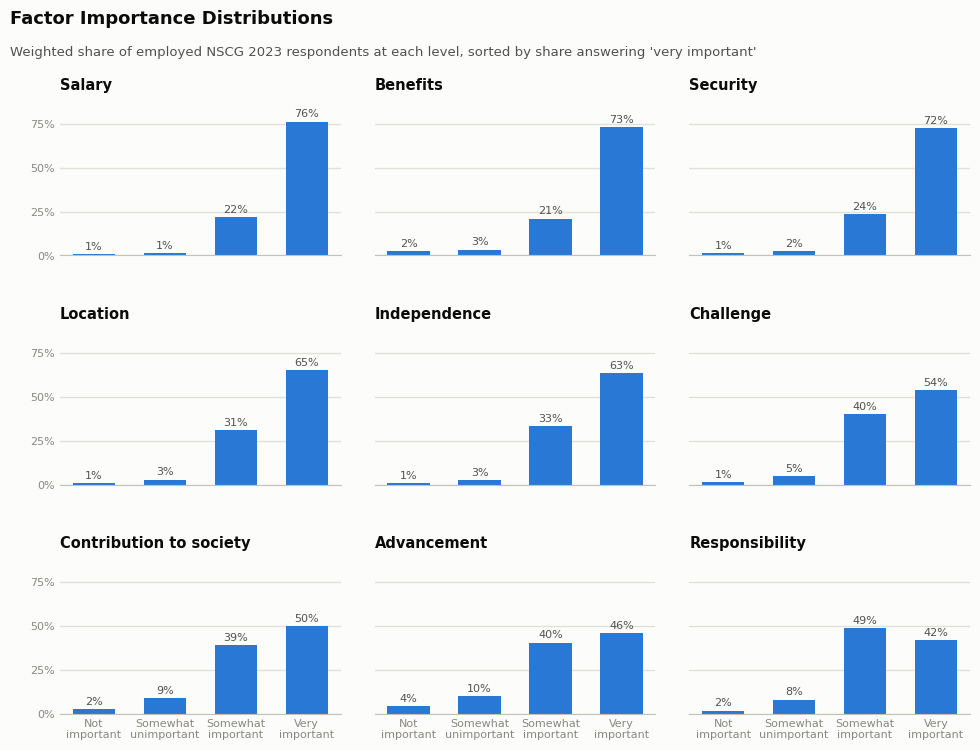

,Not important at all,Somewhat unimportant,Somewhat important,Very important
Salary,0.6,1.3,21.8,76.3
Benefits,2.3,3.3,21.0,73.3
Security,1.5,2.3,23.7,72.5
Location,1.0,2.8,31.1,65.1
Independence,0.6,2.6,33.3,63.5
Challenge,1.2,4.8,40.2,53.7
Contribution to society,2.4,8.8,38.9,49.9
Advancement,4.1,9.8,40.4,45.7
Responsibility,1.7,8.0,48.5,41.8


In [58]:
FACTOR_NAMES = {
    "ADV": "Advancement", "BEN": "Benefits", "CHAL": "Challenge", "IND": "Independence",
    "LOC": "Location", "RESP": "Responsibility", "SAL": "Salary", "SEC": "Security",
    "SOC": "Contribution to society",
}
# Reversed scale from cleaning: 1 = not important at all ... 4 = very important
LEVEL_TICKS = ["Not\nimportant", "Somewhat\nunimportant", "Somewhat\nimportant", "Very\nimportant"]
BAR = "#2a78d6"  # one series per panel, so one hue and no legend
SURFACE, INK, INK_2, MUTED, GRID, BASELINE = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"

# Weighted % of respondents at each level, one row per factor
shares = pd.DataFrame(
    {FACTOR_NAMES[f]: df.groupby(f"FAC{f}").WTSURVY.sum() / df.WTSURVY.sum() * 100 for f in FACTORS}
).T.reindex(columns=[1, 2, 3, 4], fill_value=0)
shares = shares.sort_values(4, ascending=False)  # panels read from most to least "very important"

fig, axes = plt.subplots(3, 3, figsize=(10, 8), sharex=True, sharey=True, facecolor=SURFACE)
for ax, (name, row) in zip(axes.flat, shares.iterrows()):
    ax.set_facecolor(SURFACE)
    ax.bar(range(4), row.values, width=0.6, color=BAR, zorder=2)
    for x, v in enumerate(row.values):
        ax.text(x, v + 1.5, f"{v:.0f}%", ha="center", va="bottom", color=INK_2, fontsize=8)
    ax.set_title(name, loc="left", color=INK, fontsize=10.5, fontweight="semibold")
    ax.set_ylim(0, 90)
    ax.yaxis.set_major_formatter(PercentFormatter(decimals=0))
    ax.set_yticks([0, 25, 50, 75])
    ax.grid(axis="y", color=GRID, linewidth=1, zorder=0)
    ax.tick_params(length=0, colors=MUTED, labelsize=8)
    for side in ["top", "right", "left"]:
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(BASELINE)

for ax in axes[-1]:
    ax.set_xticks(range(4))
    ax.set_xticklabels(LEVEL_TICKS, color=MUTED, fontsize=8)

fig.subplots_adjust(left=0.07, right=0.98, top=0.86, bottom=0.09, hspace=0.45, wspace=0.12)
fig.text(0.02, 0.97, "Factor Importance Distributions",
         color=INK, fontsize=13, fontweight="semibold", va="top")
fig.text(0.02, 0.925, "Weighted share of employed NSCG 2023 respondents at each level, sorted by share answering 'very important'",
         color=INK_2, fontsize=9.5, va="top")
plt.show()

# Same numbers as a table, for exact values
LEVELS = {1: "Not important at all", 2: "Somewhat unimportant", 3: "Somewhat important", 4: "Very important"}
shares.rename(columns=LEVELS).round(1)

**What this shows**

- **Ceiling effect.** Every factor is "important" to 86–98% of respondents, so whether someone rates a factor important at all says little about them.
- **The variation is in "very important".** It ranges from 76% for salary to 42% for responsibility. Salary, benefits and security are near-universal priorities; responsibility, advancement and contribution to society split respondents most.
- **Implication for fit features.** Because importance has so little spread, person-job fit will likely need to use "very important" vs not (or the full scale relative to each person's own average) rather than the raw 1–4 score.

## 8. Correlations among the importance items

Spearman rank correlations between the nine `FAC*` items and the target `very_satisfied`. Spearman suits these 1-4 ordered scales better than Pearson, since it only assumes the levels are ordered, not evenly spaced. Correlations are unweighted.

Only the lower triangle is shown, since the matrix is symmetric.

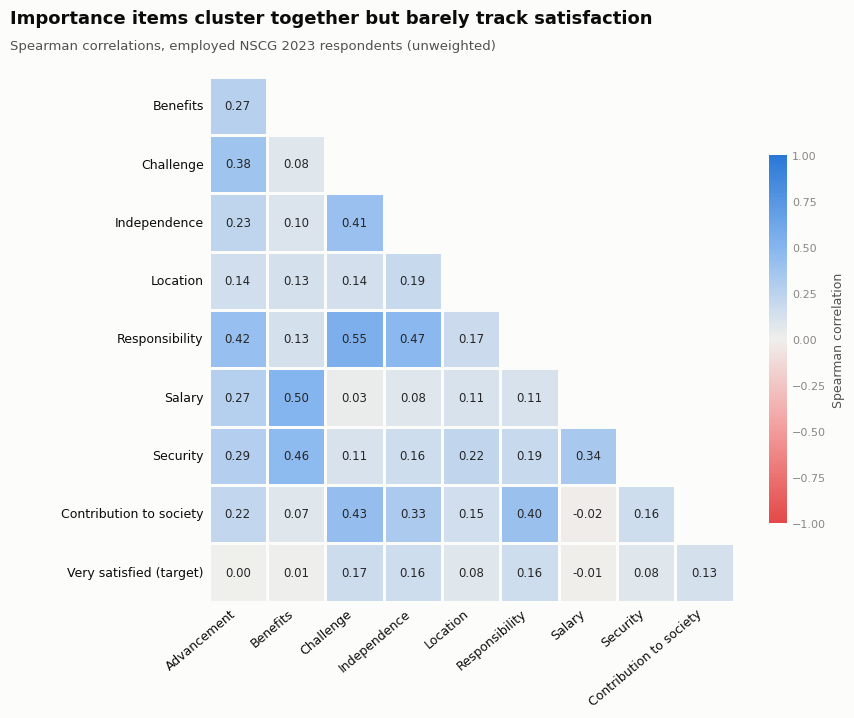

In [59]:
HEAT_COLS = FAC_COLS + ["very_satisfied"]
HEAT_NAMES = {f"FAC{f}": FACTOR_NAMES[f] for f in FACTORS} | {"very_satisfied": "Very satisfied (target)"}

corr = df[HEAT_COLS].corr(method="spearman").rename(index=HEAT_NAMES, columns=HEAT_NAMES)
# Lower triangle only: drop the first row and last column (they'd be empty), then hide the upper half
lower = corr.iloc[1:, :-1]
mask = np.triu(np.ones_like(lower, dtype=bool), k=1)

# Diverging: red (negative) <-> neutral gray at 0 <-> blue (positive)
DIVERGING = LinearSegmentedColormap.from_list(
    "red_gray_blue", ["#e34948", "#f29c9b", "#f0efec", "#86b6ef", "#2a78d6"]
)

fig, ax = plt.subplots(figsize=(9, 7.5), facecolor=SURFACE)
ax.set_facecolor(SURFACE)
sns.heatmap(
    lower, mask=mask, cmap=DIVERGING, vmin=-1, vmax=1, center=0,
    annot=True, fmt=".2f", annot_kws={"fontsize": 8.5},
    linewidths=2, linecolor=SURFACE, square=True,
    cbar_kws={"shrink": 0.7, "label": "Spearman correlation"}, ax=ax,
)
ax.tick_params(length=0, colors=INK, labelsize=9)
plt.setp(ax.get_xticklabels(), rotation=40, ha="right")
cbar = ax.collections[0].colorbar
cbar.ax.tick_params(length=0, colors=MUTED, labelsize=8)
cbar.outline.set_visible(False)
cbar.set_label("Spearman correlation", color=INK_2, fontsize=9)

fig.text(0.02, 0.97, "Importance items cluster together but barely track satisfaction",
         color=INK, fontsize=13, fontweight="semibold", va="top")
fig.text(0.02, 0.93, "Spearman correlations, employed NSCG 2023 respondents (unweighted)",
         color=INK_2, fontsize=9.5, va="top")
fig.subplots_adjust(top=0.88, left=0.2, right=0.98, bottom=0.18)
plt.show()

**What this shows**

- **Two clusters of values.** Extrinsic factors move together: salary, benefits and security (0.34-0.50). So do intrinsic ones: challenge, responsibility, independence and contribution to society (0.33-0.55). People who value one factor in a cluster tend to value the others, so the nine items carry less independent information than nine columns suggest.
- **Weak links to the target.** No item correlates with `very_satisfied` above 0.17; the intrinsic factors are the strongest (challenge 0.17, independence and responsibility 0.16). Salary, benefits and advancement are essentially zero.
- **Implication.** What someone values doesn't predict their satisfaction on its own, which is expected: fit should come from comparing these values with what the job offers.

## 9. Skewness

Two shape statistics for each numeric column:

- **Skewness**: which side the long tail is on. 0 is symmetric; positive means a long right tail (a few very large values, e.g. salary); negative means a long left tail. |skew| > 1 is usually called heavily skewed.
- **Excess kurtosis**: how heavy the tails are compared with a normal distribution. 0 matches a normal curve; > 0 means more extreme outliers; < 0 means flatter, with no extremes. Values above 3 are flagged.

Both are unweighted (they describe the sample).

In [60]:
# Shared chart helpers for sections 9-14
ACCENT = "#2a78d6"  # single-series hue


def thousands(v, _=None):
    return f"{v / 1000:g}K" if abs(v) >= 1000 else f"{v:.0f}"


def style_ax(ax, grid="y"):
    ax.set_facecolor(SURFACE)
    ax.grid(axis=grid, color=GRID, linewidth=1, zorder=0)
    ax.set_axisbelow(True)
    ax.tick_params(length=0, colors=MUTED, labelsize=8.5)
    for side in ["top", "right", "left", "bottom"]:
        ax.spines[side].set_visible(False)
    ax.spines["bottom" if grid == "y" else "left"].set_visible(True)
    ax.spines["bottom" if grid == "y" else "left"].set_color(BASELINE)


def title_block(fig, title, subtitle):
    # Fixed offsets in inches, so title spacing doesn't depend on figure height
    h = fig.get_figheight()
    fig.text(0.02, 1 - 0.15 / h, title, color=INK, fontsize=13, fontweight="semibold", va="top")
    fig.text(0.02, 1 - 0.47 / h, subtitle, color=INK_2, fontsize=9.5, va="top")


SKEW_COLS = (
    ["SALARY", "log_salary", "EARN", "HRSWK", "WKSWK", "AGE", "tenure_years", "years_since_degree",
     "WTSURVY", "job_zone"] + VALUES + ["JOBSATIS"] + SAT_COLS + FAC_COLS
)
shape = pd.DataFrame({"skewness": df[SKEW_COLS].skew(), "excess_kurtosis": df[SKEW_COLS].kurt()}).round(2)
shape["heavily_skewed"] = shape.skewness.abs() > 1
shape["heavy_tails"] = shape.excess_kurtosis > 3
shape.sort_values("skewness", key=abs, ascending=False)

/var/folders/ny/p5hb2xbx46g25_c_0lg5mhyc0000gn/T/ipykernel_3446/2611418413.py:32: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  shape["heavily_skewed"] = shape.skewness.abs() > 1
/var/folders/ny/p5hb2xbx46g25_c_0lg5mhyc0000gn/T/ipykernel_344

,skewness,excess_kurtosis,heavily_skewed,heavy_tails
WTSURVY,9.95,198.08,True,True
EARN,6.56,61.87,True,True
SALARY,4.71,38.62,True,True
WKSWK,-4.61,25.22,True,True
FACBEN,-2.23,5.60,True,True
tenure_years,2.01,4.27,True,True
FACSAL,-1.95,4.42,True,True
log_salary,-1.92,8.93,True,True
FACSEC,-1.90,4.08,True,True
SATIND,-1.52,2.17,True,False


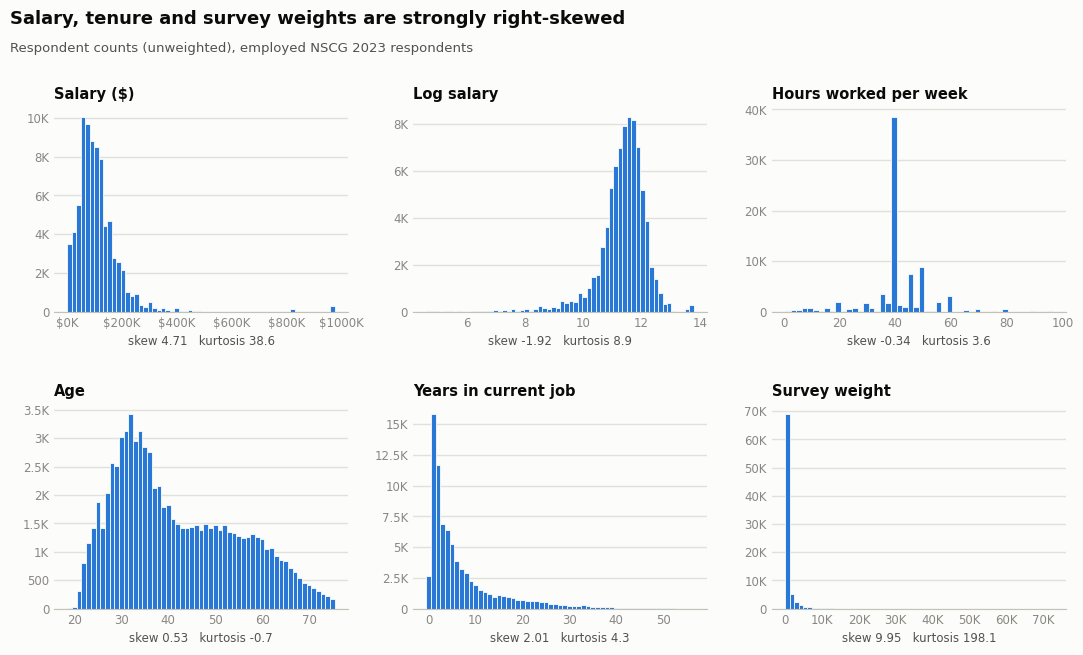

In [61]:
# Whole-number columns get one bin per value (or per 2 hours) so bins line up with the data
HIST = [
    ("SALARY", "Salary ($)", 60),
    ("log_salary", "Log salary", 60),
    ("HRSWK", "Hours worked per week", np.arange(0.5, 98.5, 2)),
    ("AGE", "Age", np.arange(18.5, 76.5)),
    ("tenure_years", "Years in current job", np.arange(-0.5, 57.5)),
    ("WTSURVY", "Survey weight", 60),
]

fig, axes = plt.subplots(2, 3, figsize=(11, 6.6), facecolor=SURFACE)
for ax, (col, label, bins) in zip(axes.flat, HIST):
    style_ax(ax)
    ax.hist(df[col].dropna(), bins=bins, color=ACCENT, edgecolor=SURFACE, linewidth=0.6, zorder=2)
    ax.set_title(label, loc="left", color=INK, fontsize=10.5, fontweight="semibold")
    ax.set_xlabel(f"skew {shape.loc[col, 'skewness']:.2f}   kurtosis {shape.loc[col, 'excess_kurtosis']:.1f}",
                  color=INK_2, fontsize=8.5)
    ax.yaxis.set_major_formatter(thousands)
axes[0, 0].xaxis.set_major_formatter(lambda v, _: f"${v / 1000:.0f}K")
axes[1, 2].xaxis.set_major_formatter(thousands)

title_block(fig, "Salary, tenure and survey weights are strongly right-skewed",
            "Respondent counts (unweighted), employed NSCG 2023 respondents")
fig.subplots_adjust(left=0.06, right=0.98, top=0.83, bottom=0.07, hspace=0.45, wspace=0.22)
plt.show()

**What this shows**

- **Salary** is heavily right-skewed (skew 4.71, kurtosis 38.6), with a spike at the \$977K top-code. Logging it overcorrects: `log_salary` is left-skewed (−1.92) because of the 212 implausibly low salaries flagged in cleaning. For modeling, log salary plus the existing salary flags (or capping the very low values) will behave better than raw salary.
- **Survey weights** are the most extreme column (skew 9.95, kurtosis 198): the top 1% of respondents carry 17.6% of the total weight. Kish's effective sample size is about **11,400 of 79,800**, so weighted estimates are much noisier than the raw count suggests. The confidence intervals in sections 13-14 account for this.
- **Tenure** is right-skewed (2.01): 38% of respondents have been in their current job 2 years or less, and 46% started it in 2020-2023.
- **The 1-4 scales are skewed toward the top**, most strongly benefits, salary and security importance (skew about −2), matching the ceiling effect in section 7.
- **Hours** look symmetric (skew −0.34) but have heavy tails (kurtosis 3.6): a tall spike at 40 hours with long tails either side.
- Age and years since degree are close to symmetric.

## 10. Frequency distributions

Weighted share of respondents at each level of the categorical columns, then the satisfaction side: the nine `SAT*` facets (reversed in cleaning, so 4 = very satisfied).

/var/folders/ny/p5hb2xbx46g25_c_0lg5mhyc0000gn/T/ipykernel_3446/2000862830.py:7: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  df["employer_size"] = pd.Categorical(df.EMSIZE.map(EMSIZE_LABELS), categories=EMSIZE_LABELS.values(), ordered=True

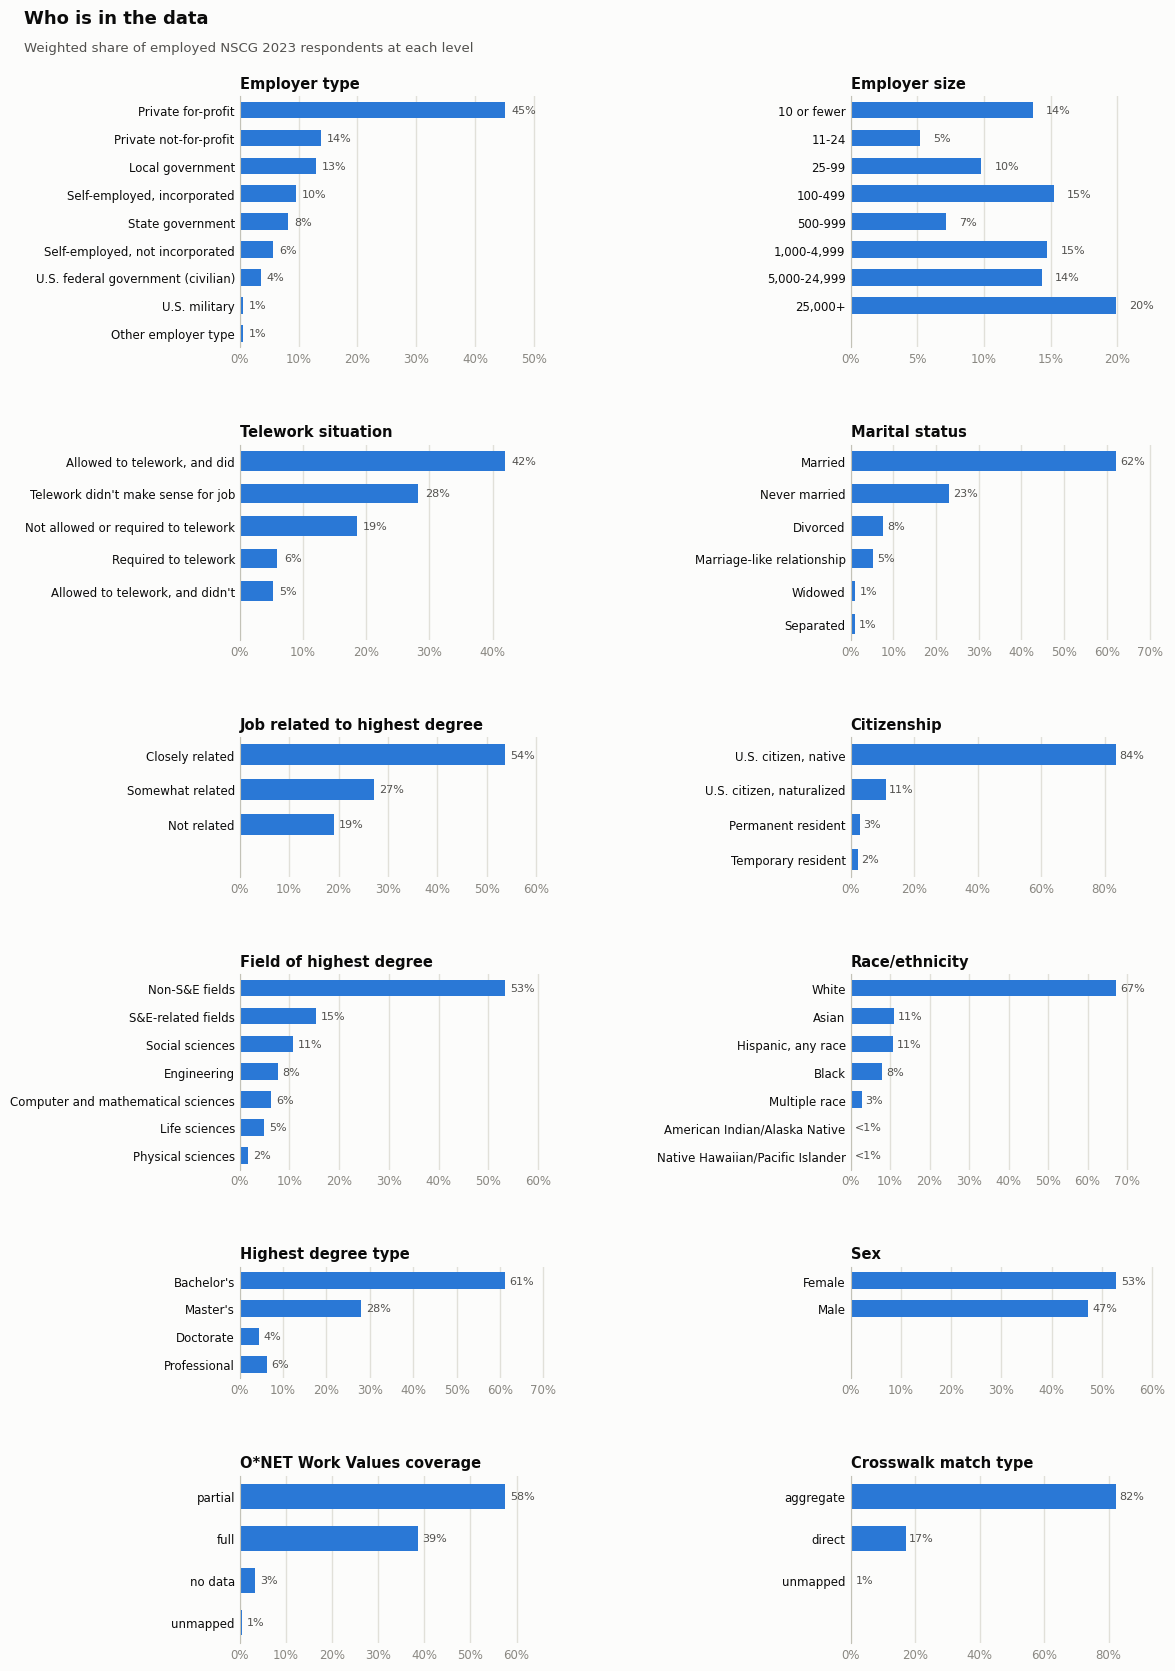

In [62]:
# Display labels for the ordered codes kept numeric in cleaning (codebook Ppcg23.sas)
EMSIZE_LABELS = {1: "10 or fewer", 2: "11-24", 3: "25-99", 4: "100-499", 5: "500-999",
                 6: "1,000-4,999", 7: "5,000-24,999", 8: "25,000+"}
OCEDRLP_LABELS = {1: "Closely related", 2: "Somewhat related", 3: "Not related"}
DEGREE_ORDER = ["Bachelor's", "Master's", "Doctorate", "Professional"]

df["employer_size"] = pd.Categorical(df.EMSIZE.map(EMSIZE_LABELS), categories=EMSIZE_LABELS.values(), ordered=True)
df["job_degree_relation"] = pd.Categorical(df.OCEDRLP.map(OCEDRLP_LABELS), categories=OCEDRLP_LABELS.values(), ordered=True)
df["DGRDG"] = df.DGRDG.cat.reorder_categories(DEGREE_ORDER, ordered=True)

FREQ = {
    "NEDTP": "Employer type", "employer_size": "Employer size", "TELEC": "Telework situation",
    "job_degree_relation": "Job related to highest degree", "NDGMEMG": "Field of highest degree",
    "DGRDG": "Highest degree type", "SEX_2023": "Sex", "RACETHM": "Race/ethnicity",
    "CTZN": "Citizenship", "MARSTA": "Marital status", "mapping_type": "Crosswalk match type",
    "wv_status": "O*NET Work Values coverage",
}
ORDERED = {"employer_size", "job_degree_relation", "DGRDG"}  # keep level order; sort the rest by share


def weighted_share(col):
    s = df.groupby(col, observed=True).WTSURVY.sum() / df.WTSURVY.sum() * 100
    return s if col in ORDERED else s.sort_values(ascending=False)


shares_by_col = {col: weighted_share(col) for col in FREQ}

fig, axes = plt.subplots(6, 2, figsize=(12, 17), facecolor=SURFACE,
                         gridspec_kw={"height_ratios": [9, 7, 5, 7, 4, 6]})
order = ["NEDTP", "employer_size", "TELEC", "MARSTA", "job_degree_relation", "CTZN",
         "NDGMEMG", "RACETHM", "DGRDG", "SEX_2023", "wv_status", "mapping_type"]
# Fill row by row: (left, right) pairs with similar level counts share a row
for i, (ax, col) in enumerate(zip(axes.flat, order)):
    s = shares_by_col[col]
    row_levels = max(len(shares_by_col[c]) for c in order[i - i % 2: i - i % 2 + 2])
    style_ax(ax, grid="x")
    y = row_levels - 1 - np.arange(len(s))
    ax.barh(y, s.values, height=0.6, color=ACCENT, zorder=2)
    ax.set_ylim(-0.5, row_levels - 0.5)
    for yi, v in zip(y, s.values):
        ax.text(v + 1, yi, "<1%" if v < 0.5 else f"{v:.0f}%", va="center", color=INK_2, fontsize=8)
    ax.set_yticks(y)
    ax.set_yticklabels(s.index, color=INK, fontsize=8.5)
    ax.set_xlim(0, max(s.max() * 1.18, 10))
    ax.xaxis.set_major_formatter(PercentFormatter(decimals=0))
    ax.set_title(FREQ[col], loc="left", color=INK, fontsize=10.5, fontweight="semibold")

title_block(fig, "Who is in the data",
            "Weighted share of employed NSCG 2023 respondents at each level")
fig.subplots_adjust(left=0.2, right=0.97, top=0.94, bottom=0.03, hspace=0.55, wspace=0.95)
plt.show()

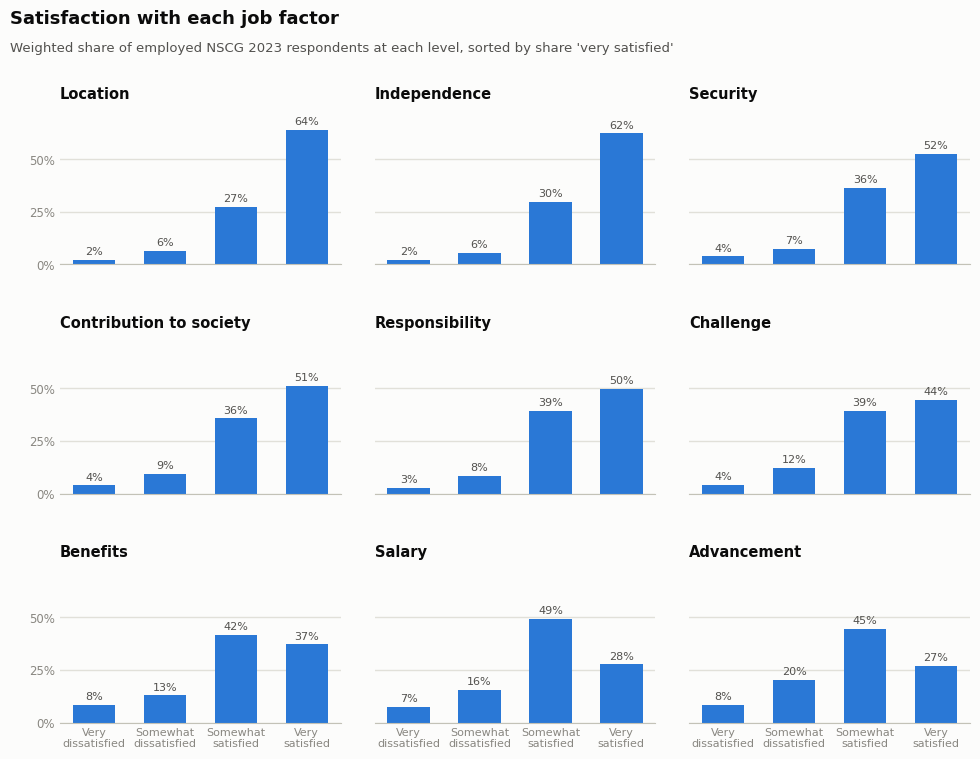

Overall job satisfaction (JOBSATIS, codebook order 1 = very satisfied), weighted %:
JOBSATIS
Very satisfied           44.1
Somewhat satisfied       45.8
Somewhat dissatisfied     7.8
Very dissatisfied         2.3


,1,2,3,4
Location,2.1,6.4,27.4,64.1
Independence,2.3,5.6,29.8,62.2
Security,3.9,7.3,36.2,52.5
Contribution to society,3.9,9.4,35.7,51.0
Responsibility,2.7,8.4,39.1,49.8
Challenge,4.3,12.0,39.3,44.4
Benefits,8.3,13.0,41.6,37.2
Salary,7.3,15.6,49.4,27.7
Advancement,8.4,20.2,44.5,27.0


In [63]:
SAT_TICKS = ["Very\ndissatisfied", "Somewhat\ndissatisfied", "Somewhat\nsatisfied", "Very\nsatisfied"]

sat_shares = pd.DataFrame(
    {FACTOR_NAMES[f]: df.groupby(f"SAT{f}").WTSURVY.sum() / df.WTSURVY.sum() * 100 for f in FACTORS}
).T.reindex(columns=[1, 2, 3, 4], fill_value=0)
sat_shares = sat_shares.sort_values(4, ascending=False)

fig, axes = plt.subplots(3, 3, figsize=(10, 8), sharex=True, sharey=True, facecolor=SURFACE)
for ax, (name, row) in zip(axes.flat, sat_shares.iterrows()):
    style_ax(ax)
    ax.bar(range(4), row.values, width=0.6, color=ACCENT, zorder=2)
    for x, v in enumerate(row.values):
        ax.text(x, v + 1.5, f"{v:.0f}%", ha="center", va="bottom", color=INK_2, fontsize=8)
    ax.set_title(name, loc="left", color=INK, fontsize=10.5, fontweight="semibold")
    ax.set_ylim(0, 75)
    ax.set_yticks([0, 25, 50])
    ax.yaxis.set_major_formatter(PercentFormatter(decimals=0))
for ax in axes[-1]:
    ax.set_xticks(range(4))
    ax.set_xticklabels(SAT_TICKS, color=MUTED, fontsize=8)

title_block(fig, "Satisfaction with each job factor",
            "Weighted share of employed NSCG 2023 respondents at each level, sorted by share 'very satisfied'")
fig.subplots_adjust(left=0.07, right=0.98, top=0.86, bottom=0.09, hspace=0.45, wspace=0.12)
plt.show()

overall = (df.groupby("JOBSATIS").WTSURVY.sum() / df.WTSURVY.sum() * 100).round(1)
print("Overall job satisfaction (JOBSATIS, codebook order 1 = very satisfied), weighted %:")
print(overall.rename({1: "Very satisfied", 2: "Somewhat satisfied", 3: "Somewhat dissatisfied", 4: "Very dissatisfied"}).to_string())
sat_shares.round(1)

**What this shows**

- **Sample profile (weighted)**: 45% work for private for-profit employers, 61% hold a bachelor's as their highest degree, 53% have a non-S&E degree, 84% are native-born U.S. citizens and 53% are women. 42% teleworked, and 54% say their job is closely related to their degree.
- **Satisfaction facets**: people are most often very satisfied with location (64%) and independence (62%), and least with advancement (27%) and salary (28%). Advancement has the most dissatisfaction (29% somewhat or very dissatisfied), followed by salary (23%) and benefits (21%).
- **Overall job satisfaction** (`JOBSATIS`) is 44.1% very satisfied, 45.8% somewhat satisfied, 7.8% somewhat dissatisfied and 2.3% very dissatisfied, so the binary target's negative class is mostly "somewhat satisfied".

## 11. Cardinality

How many distinct levels each categorical or code column has, and how many of those levels are rare. High-cardinality columns can't be one-hot encoded sensibly for modeling: most of the resulting columns would describe a handful of respondents.

In [64]:
# NCSES minor occupation group = first two digits of N3OCPR (labels from Table A-2)
with warnings.catch_warnings():
    warnings.simplefilter("ignore", UserWarning)  # openpyxl: "no default style", harmless
    a2 = pd.read_excel(DATA / "reference" / "nsf25322-taba-002.xlsx", header=None, skiprows=5)
minor = a2[[4, 5]].dropna().astype({4: int})
MINOR_LABELS = dict(zip(minor[4].astype(str), minor[5].str.strip()))
df["occ_minor_group"] = df.N3OCPR.str[:2].map(MINOR_LABELS).astype("category")

CARD_COLS = ["N3OCPR", "INDCODE", "occ_minor_group"] + CATEGORICAL + ["employer_size", "job_degree_relation", "TELEFR"]
rows = []
for col in dict.fromkeys(CARD_COLS):  # dedupe, keep order
    vc = df[col].value_counts()
    rows.append({
        "column": col,
        "n_levels": vc.size,
        "top_level": vc.index[0],
        "top_share_pct": round(vc.iloc[0] / vc.sum() * 100, 1),
        "levels_under_1pct": int((vc / vc.sum() < 0.01).sum()),
        "levels_under_30_resp": int((vc < 30).sum()),
        "resp_in_levels_under_30": int(vc[vc < 30].sum()),
    })
cardinality = pd.DataFrame(rows).set_index("column").sort_values("n_levels", ascending=False)
cardinality

/var/folders/ny/p5hb2xbx46g25_c_0lg5mhyc0000gn/T/ipykernel_3446/1465748722.py:7: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  df["occ_minor_group"] = df.N3OCPR.str[:2].map(MINOR_LABELS).astype("category")


,n_levels,top_level,top_share_pct,levels_under_1pct,levels_under_30_resp,resp_in_levels_under_30
column,,,,,,
INDCODE,264,7870,10.0,238,86,1275
N3OCPR,129,110590,5.1,101,1,12
ncses_label,129,Software developers – applications and systems...,5.1,101,1,12
occ_minor_group,39,Health-related occupations,11.6,19,0,0
NEDTP,9,Private for-profit,49.3,2,0,0
employer_size,8,"25,000+",24.4,0,0,0
RACETHM,7,White,54.6,2,0,0
NDGMEMG,7,Non-S&E fields,26.8,0,0,0
MARSTA,6,Married,63.6,2,0,0


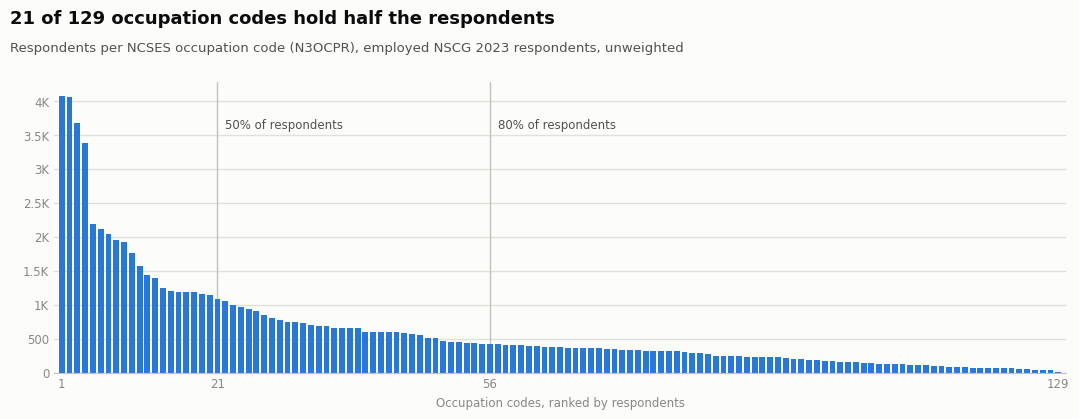

Smallest occupation codes: {'121720': 46, '282970': 45, '570920': 38, '570950': 33, '742880': 12}
Minor groups: 39 levels, smallest has 90 respondents


In [65]:
occ_counts = df.N3OCPR.value_counts()
cum = occ_counts.cumsum() / occ_counts.sum() * 100
n_half = int((cum < 50).sum()) + 1
n_80 = int((cum < 80).sum()) + 1

fig, ax = plt.subplots(figsize=(11, 4.4), facecolor=SURFACE)
style_ax(ax)
ax.bar(np.arange(len(occ_counts)), occ_counts.values, width=0.75, color=ACCENT, zorder=2)
ax.set_xlim(-1, len(occ_counts))
ax.set_xticks([0, n_half - 1, n_80 - 1, len(occ_counts) - 1])
ax.set_xticklabels(["1", f"{n_half}", f"{n_80}", f"{len(occ_counts)}"], color=MUTED)
ax.yaxis.set_major_formatter(thousands)
ax.set_xlabel("Occupation codes, ranked by respondents", color=MUTED, fontsize=8.5)
for x, txt in [(n_half - 1, "50% of respondents"), (n_80 - 1, "80% of respondents")]:
    ax.axvline(x, color=BASELINE, linewidth=1, zorder=1)
    ax.text(x + 1, occ_counts.max() * 0.92, txt, color=INK_2, fontsize=8.5, va="top")

title_block(fig, f"{n_half} of {len(occ_counts)} occupation codes hold half the respondents",
            "Respondents per NCSES occupation code (N3OCPR), employed NSCG 2023 respondents, unweighted")
fig.subplots_adjust(left=0.06, right=0.98, top=0.8, bottom=0.14)
plt.show()

print(f"Smallest occupation codes: {occ_counts.tail(5).to_dict()}")
print(f"Minor groups: {df.occ_minor_group.nunique()} levels, smallest has {df.occ_minor_group.value_counts().min()} respondents")

**What this shows**

- **Industry (`INDCODE`) has the longest tail**: 264 codes, 238 of which each hold under 1% of respondents (together a third of the sample), and 86 have fewer than 30 respondents.
- **Occupation (`N3OCPR`)**: 129 codes; 21 hold half the respondents, and the 101 codes under 1% each together cover 41%. Only one code has fewer than 30 respondents (742880, postsecondary recreation and fitness teachers, n = 12).
- **The NCSES minor group** (first two digits of `N3OCPR`) cuts occupation to 39 levels, the smallest with 90 respondents, a workable size for one-hot encoding.
- **Implication for modeling**: don't one-hot the 129 occupation or 264 industry codes. Use the minor group, the occupation's O*NET features themselves, or target encoding; group industries into broader sectors. The other categorical columns have 2-9 levels and no rare-level problems.

## 12. Correlation coefficients

Three views of how columns relate to each other and to satisfaction:

1. **Spearman correlation with `very_satisfied`** for every numeric and True/False feature. Spearman uses ranks, so it works for scales and skewed amounts alike. The `SAT*` facets are shown separately: they measure the outcome, so they're for validation only, never features.
2. **Cramér's V** for the categorical columns, which have no order to correlate. It runs from 0 (no association with `very_satisfied`) to 1 (perfect association).
3. **Person-job block**: how the nine importance items (`FAC*`, person side) correlate with the six O*NET Work Values of the respondent's occupation (job side). Correlations are unweighted.

/var/folders/ny/p5hb2xbx46g25_c_0lg5mhyc0000gn/T/ipykernel_3446/299596964.py:1: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  df["job_degree_relatedness"] = 4 - df.OCEDRLP  # 3 = closely related, so higher = more related


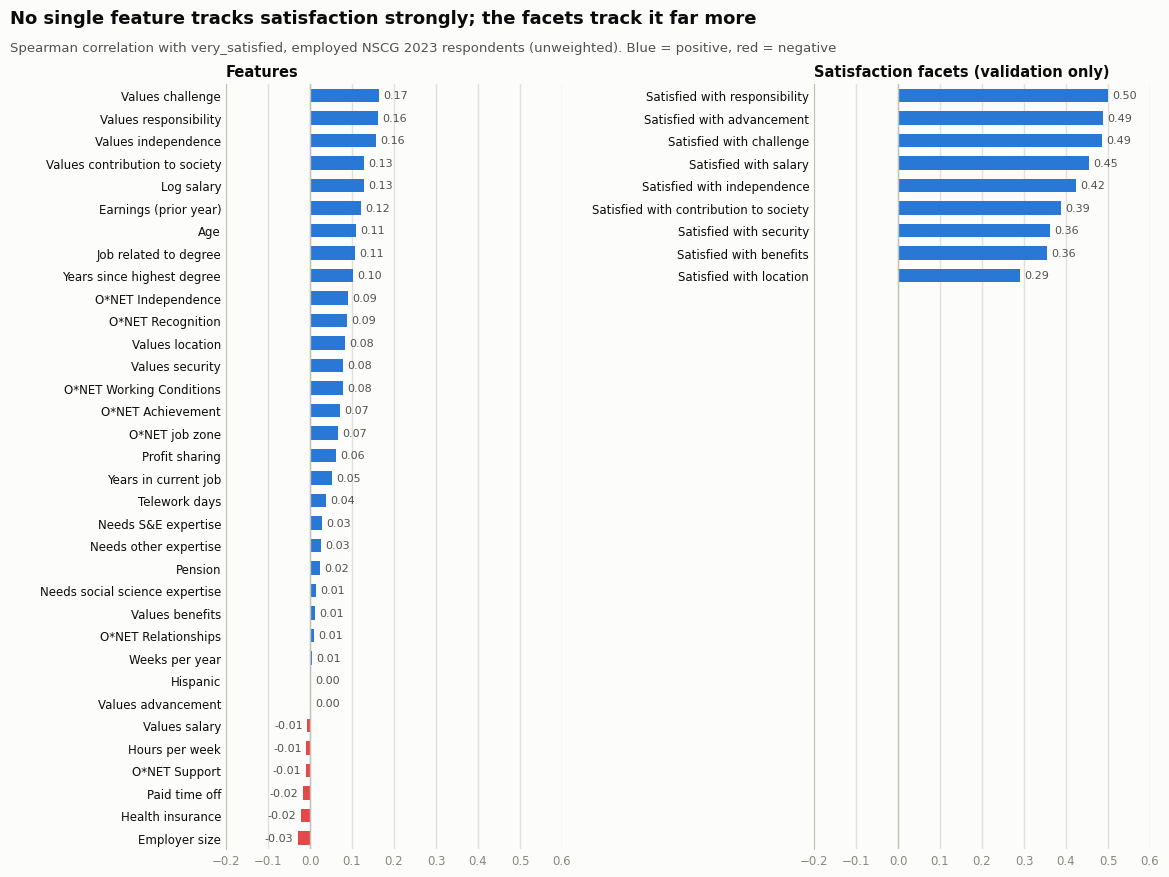

In [66]:
df["job_degree_relatedness"] = 4 - df.OCEDRLP  # 3 = closely related, so higher = more related

FEATURES = {
    "log_salary": "Log salary", "EARN": "Earnings (prior year)", "HRSWK": "Hours per week",
    "WKSWK": "Weeks per year", "AGE": "Age", "tenure_years": "Years in current job",
    "years_since_degree": "Years since highest degree", "TELEFR": "Telework days",
    "EMSIZE": "Employer size", "job_degree_relatedness": "Job related to degree",
    "MGRNAT": "Needs S&E expertise", "MGRSOC": "Needs social science expertise",
    "MGROTH": "Needs other expertise", "JOBINS": "Health insurance", "JOBPENS": "Pension",
    "JOBPROFT": "Profit sharing", "JOBVAC": "Paid time off", "HISPANIC": "Hispanic",
    "job_zone": "O*NET job zone",
} | {v: f"O*NET {v}" for v in VALUES} | {f"FAC{f}": f"Values {FACTOR_NAMES[f].lower()}" for f in FACTORS}

target_corr = (
    df[list(FEATURES)].astype(float).corrwith(df.very_satisfied, method="spearman")
    .rename(FEATURES).sort_values()
)
sat_corr = (
    df[SAT_COLS].corrwith(df.very_satisfied, method="spearman")
    .rename({f"SAT{f}": f"Satisfied with {FACTOR_NAMES[f].lower()}" for f in FACTORS}).sort_values()
)

POS, NEG = "#2a78d6", "#e34948"
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 9), sharex=True, facecolor=SURFACE,
                               gridspec_kw={"width_ratios": [1, 1], "wspace": 0.75})
for ax, s, title in [(ax1, target_corr, "Features"), (ax2, sat_corr, "Satisfaction facets (validation only)")]:
    style_ax(ax, grid="x")
    y = np.arange(len(s))
    ax.barh(y, s.values, height=0.6, color=[POS if v >= 0 else NEG for v in s.values], zorder=2)
    ax.axvline(0, color=BASELINE, linewidth=1, zorder=3)
    for yi, v in zip(y, s.values):
        ax.text(v + (0.01 if v >= 0 else -0.01), yi, f"{v:.2f}", va="center",
                ha="left" if v >= 0 else "right", color=INK_2, fontsize=8)
    ax.set_yticks(y)
    ax.set_yticklabels(s.index, color=INK, fontsize=8.5)
    ax.set_title(title, loc="left", color=INK, fontsize=10.5, fontweight="semibold")
    ax.set_ylim(len(s) - len(target_corr) - 0.5, len(s) - 0.5)  # bars at the top, same thickness in both panels
ax1.set_xlim(-0.2, 0.6)

title_block(fig, "No single feature tracks satisfaction strongly; the facets track it far more",
            "Spearman correlation with very_satisfied, employed NSCG 2023 respondents (unweighted). Blue = positive, red = negative")
fig.subplots_adjust(left=0.2, right=0.97, top=0.9, bottom=0.05)
plt.show()

In [67]:
def cramers_v(x, y):
    table = pd.crosstab(x, y)
    chi2 = chi2_contingency(table, correction=False)[0]
    r, k = table.shape
    return np.sqrt(chi2 / (table.values.sum() * (min(r, k) - 1)))


CAT_FOR_V = {"NEDTP": "Employer type", "NDGMEMG": "Field of highest degree", "DGRDG": "Highest degree type",
             "SEX_2023": "Sex", "RACETHM": "Race/ethnicity", "CTZN": "Citizenship", "MARSTA": "Marital status",
             "TELEC": "Telework situation", "occ_minor_group": "Occupation minor group",
             "ncses_label": "Occupation (129 codes)", "wv_status": "Work Values coverage",
             "mapping_type": "Crosswalk match type"}
pd.Series({label: cramers_v(df[col], df.very_satisfied) for col, label in CAT_FOR_V.items()},
          name="Cramér's V with very_satisfied").sort_values(ascending=False).round(3).to_frame()

,Cramér's V with very_satisfied
Occupation (129 codes),0.129
Telework situation,0.113
Marital status,0.108
Race/ethnicity,0.098
Employer type,0.091
Occupation minor group,0.090
Citizenship,0.067
Highest degree type,0.043
Sex,0.034
Field of highest degree,0.029


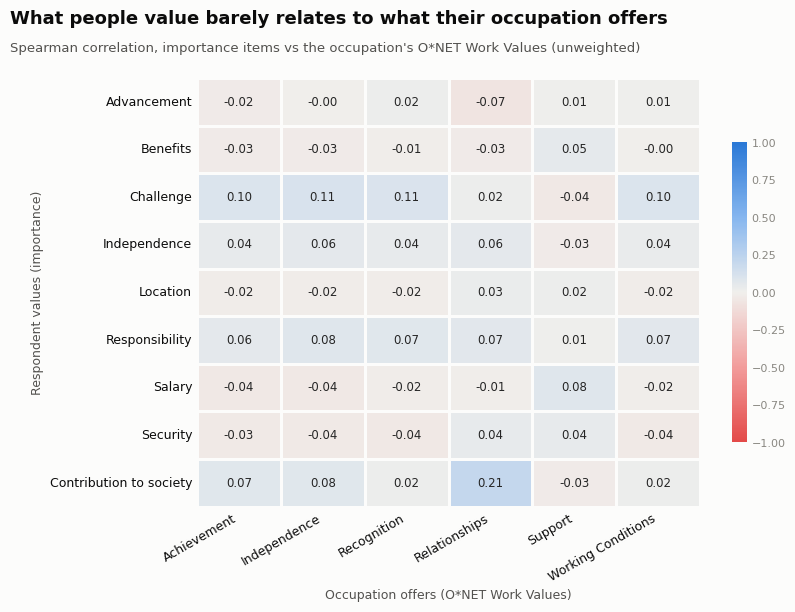

In [68]:
pj = df[FAC_COLS + VALUES].corr(method="spearman").loc[FAC_COLS, VALUES]
pj.index = [FACTOR_NAMES[c[3:]] for c in pj.index]

fig, ax = plt.subplots(figsize=(8.5, 6.4), facecolor=SURFACE)
sns.heatmap(pj, cmap=DIVERGING, vmin=-1, vmax=1, center=0, annot=True, fmt=".2f",
            annot_kws={"fontsize": 8.5}, linewidths=2, linecolor=SURFACE,
            cbar_kws={"shrink": 0.7}, ax=ax)
ax.tick_params(length=0, colors=INK, labelsize=9)
ax.set_xlabel("Occupation offers (O*NET Work Values)", color=INK_2, fontsize=9)
ax.set_ylabel("Respondent values (importance)", color=INK_2, fontsize=9)
plt.setp(ax.get_xticklabels(), rotation=30, ha="right")
cbar = ax.collections[0].colorbar
cbar.ax.tick_params(length=0, colors=MUTED, labelsize=8)
cbar.outline.set_visible(False)

title_block(fig, "What people value barely relates to what their occupation offers",
            "Spearman correlation, importance items vs the occupation's O*NET Work Values (unweighted)")
fig.subplots_adjust(top=0.87, left=0.24, right=0.98, bottom=0.2)
plt.show()

**What this shows**

- **No single feature is strongly related to satisfaction.** The largest are what people value (challenge 0.17, responsibility and independence 0.16), log salary (0.13), earnings (0.12), age (0.11), job-degree relatedness (0.11) and years since degree (0.10). The O*NET Work Values sit between 0.01 and 0.09, and job zone at 0.07. Benefit flags are near zero (health insurance −0.02, paid time off −0.02), likely because almost everyone has them (86-87%).
- **The facets confirm the leakage concern**: 0.29-0.50, three times the strongest feature.
- **Among categories** (Cramér's V), the specific occupation (0.13), telework situation (0.11), marital status (0.11), race/ethnicity (0.10) and employer type (0.09) are the most associated with satisfaction; degree field (0.03) and sex (0.03) barely are.
- **Person and job sides are nearly independent.** Almost every importance-vs-Work-Value correlation is below 0.11 in size. The one notable link is contribution to society with O*NET Relationships (0.21): people who value serving society do tend to work in service-oriented occupations. Because the two sides overlap so little, a fit feature combining them carries information neither has alone.

## 13. Segmented averages

Weighted % very satisfied within each segment, with a 95% confidence interval. The interval uses each segment's effective sample size (Kish's formula, which accounts for unequal survey weights), so segments with very uneven weights get wider intervals. The gray line marks the overall rate. Segments with fewer than 100 respondents are marked with an open dot.

In [69]:
def weighted_rate(frame, by, y="very_satisfied", w="WTSURVY"):
    # Weighted % of y within each group, with a 95% CI from the Kish effective sample size
    tmp = frame.assign(_wy=frame[y] * frame[w], _w=frame[w], _w2=frame[w] ** 2)
    g = tmp.groupby(by, observed=True)
    out = pd.DataFrame({"n": g.size(), "pct": g._wy.sum() / g._w.sum() * 100,
                        "n_eff": g._w.sum() ** 2 / g._w2.sum()})
    se = np.sqrt(out.pct / 100 * (1 - out.pct / 100) / out.n_eff) * 100
    out["ci_low"], out["ci_high"] = out.pct - 1.96 * se, out.pct + 1.96 * se
    out["small_n"] = out.n < 100
    return out


OVERALL = np.average(df.very_satisfied, weights=df.WTSURVY) * 100
print(f"Overall: {OVERALL:.1f}% very satisfied (weighted)")

df["salary_decile"] = pd.qcut(df.SALARY.rank(method="first"), 10, labels=[f"D{i}" for i in range(1, 11)])
decile_ranges = df.groupby("salary_decile", observed=True).SALARY.agg(["min", "max"])
df["salary_decile"] = df.salary_decile.cat.rename_categories(
    {d: f"{d} (${r['min'] / 1000:,.0f}K-{r['max'] / 1000:,.0f}K)" for d, r in decile_ranges.iterrows()}
)
df["job_zone_group"] = pd.cut(df.job_zone, [0, 2.5, 3.5, 4.5, 5], labels=["Zone 2", "Zone 3", "Zone 4", "Zone 5"])

SEGMENTS = {
    "Employer type": "NEDTP", "Employer size": "employer_size", "Telework situation": "TELEC",
    "Job related to highest degree": "job_degree_relation", "Salary decile": "salary_decile",
    "O*NET job zone (2 = little prep, 5 = extensive)": "job_zone_group",
    "Highest degree type": "DGRDG", "Field of highest degree": "NDGMEMG", "Sex": "SEX_2023",
    "Race/ethnicity": "RACETHM", "Citizenship": "CTZN",
    "Occupation minor group": "occ_minor_group",
    "O*NET Work Values coverage": "wv_status", "Crosswalk match type": "mapping_type",
}
KEEP_ORDER = {"employer_size", "job_degree_relation", "salary_decile", "job_zone_group", "DGRDG"}
rates = {}
for label, col in SEGMENTS.items():
    r = weighted_rate(df, col)
    rates[label] = r if col in KEEP_ORDER else r.sort_values("pct", ascending=False)

spread = pd.DataFrame({
    "levels": {k: len(v) for k, v in rates.items()},
    "lowest_pct": {k: v.pct.min() for k, v in rates.items()},
    "highest_pct": {k: v.pct.max() for k, v in rates.items()},
}).assign(spread_pts=lambda d: d.highest_pct - d.lowest_pct).sort_values("spread_pts", ascending=False).round(1)
spread

Overall: 44.1% very satisfied (weighted)


/var/folders/ny/p5hb2xbx46g25_c_0lg5mhyc0000gn/T/ipykernel_3446/1751323456.py:16: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  df["salary_decile"] = pd.qcut(df.SALARY.rank(method="first"), 10, labels=[f"D{i}" for i in range(1, 11)])
/var/fo

,levels,lowest_pct,highest_pct,spread_pts
Occupation minor group,39,33.5,58.3,24.8
Telework situation,5,33.9,58.6,24.7
Salary decile,10,35.9,59.4,23.4
Employer type,9,36.2,58.5,22.2
Race/ethnicity,7,28.3,49.4,21.1
Employer size,8,39.7,55.1,15.4
Job related to highest degree,3,36.3,49.0,12.7
"O*NET job zone (2 = little prep, 5 = extensive)",4,34.4,47.0,12.6
Highest degree type,4,42.4,53.0,10.6
Citizenship,4,34.9,45.3,10.4


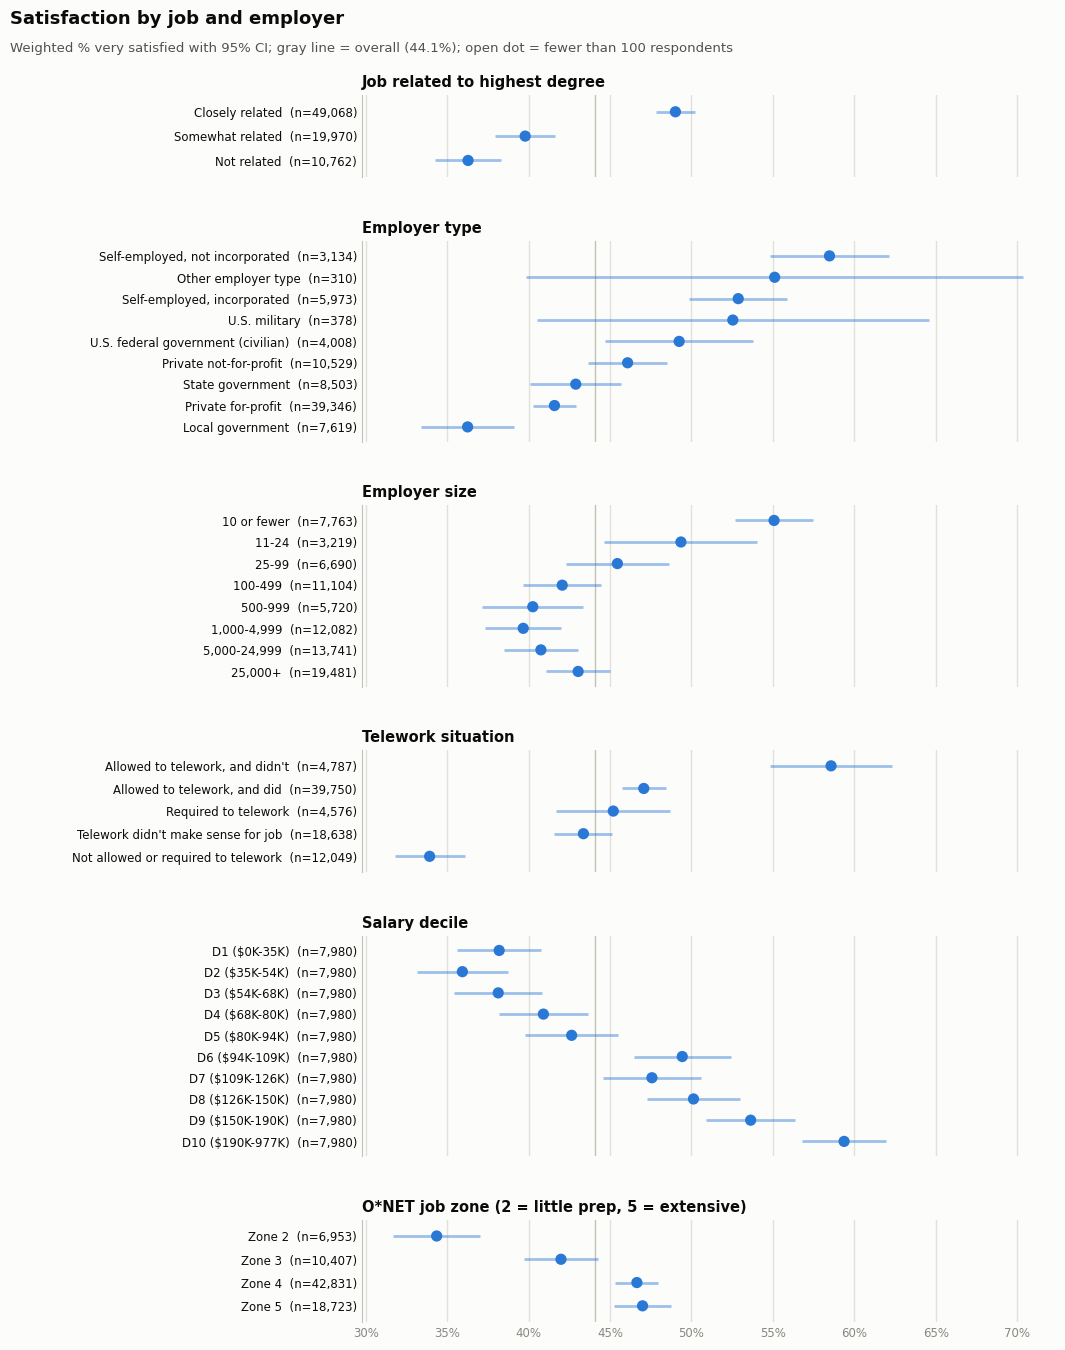

In [70]:
def plot_segments(families, title, subtitle, width=11):
    heights = [len(rates[f]) + 1.2 for f in families]
    fig, axes = plt.subplots(len(families), 1, figsize=(width, 0.27 * sum(heights) + 1.2), sharex=True,
                             facecolor=SURFACE, gridspec_kw={"height_ratios": heights})
    for ax, fam in zip(np.atleast_1d(axes), families):
        r = rates[fam]
        style_ax(ax, grid="x")
        y = np.arange(len(r))[::-1]
        ax.hlines(y, r.ci_low, r.ci_high, color=ACCENT, linewidth=2, alpha=0.45, zorder=2)
        ax.scatter(r.pct, y, s=42, zorder=3, color=[SURFACE if s else ACCENT for s in r.small_n],
                   edgecolor=ACCENT, linewidth=1.6)
        ax.axvline(OVERALL, color=BASELINE, linewidth=1, zorder=1)
        ax.set_yticks(y)
        ax.set_yticklabels([f"{i}  (n={n:,})" for i, n in zip(r.index, r.n)], color=INK, fontsize=8.5)
        ax.set_ylim(-0.7, len(r) - 0.3)
        ax.set_title(fam, loc="left", color=INK, fontsize=10.5, fontweight="semibold")
        ax.xaxis.set_major_formatter(PercentFormatter(decimals=0))
    title_block(fig, title, subtitle)
    h = fig.get_figheight()
    top, bottom = 1 - 1.0 / h, 0.4 / h
    avg_axes_in = (top - bottom) * h / (len(families) + 0.75 * (len(families) - 1))
    fig.subplots_adjust(left=0.34, right=0.97, top=top, bottom=bottom, hspace=0.75 * 0.27 * 2.6 / avg_axes_in)
    plt.show()


SUB = f"Weighted % very satisfied with 95% CI; gray line = overall ({OVERALL:.1f}%); open dot = fewer than 100 respondents"
plot_segments(["Job related to highest degree", "Employer type", "Employer size", "Telework situation",
               "Salary decile", "O*NET job zone (2 = little prep, 5 = extensive)"],
              "Satisfaction by job and employer", SUB)

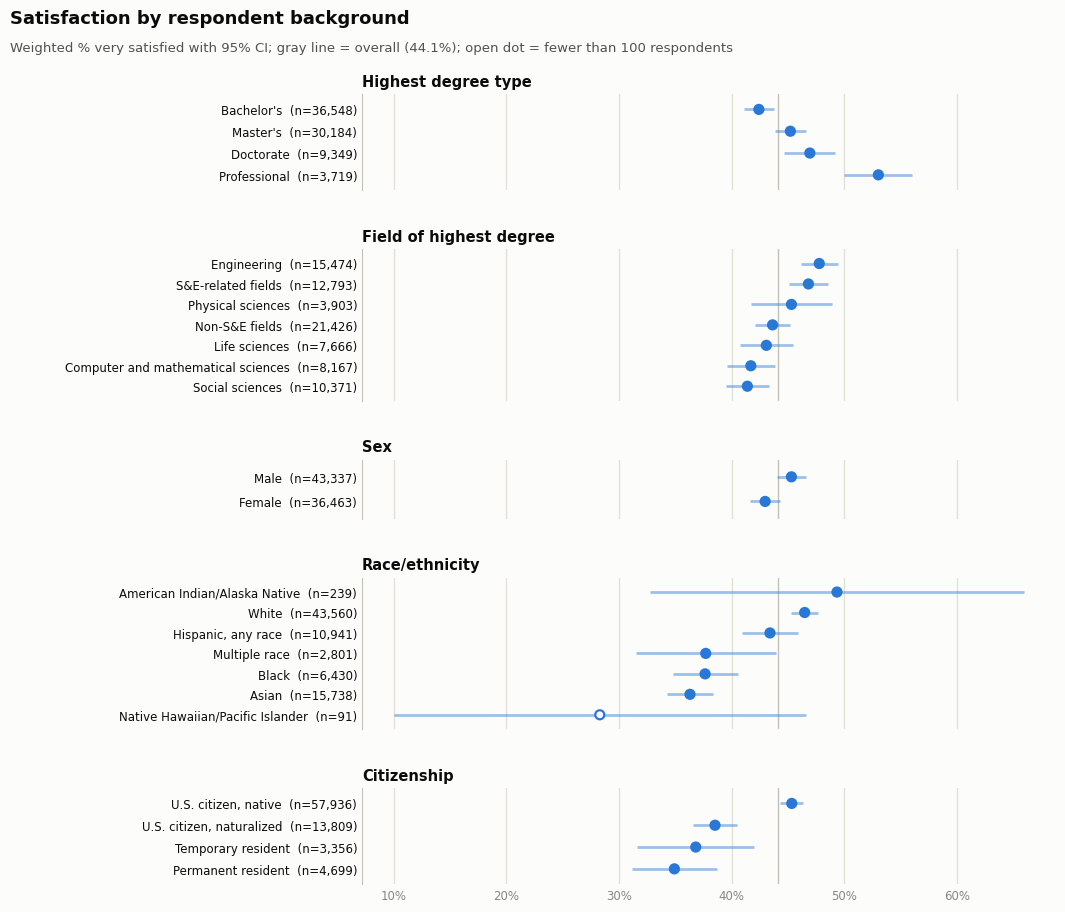

In [71]:
plot_segments(["Highest degree type", "Field of highest degree", "Sex", "Race/ethnicity", "Citizenship"],
              "Satisfaction by respondent background", SUB)

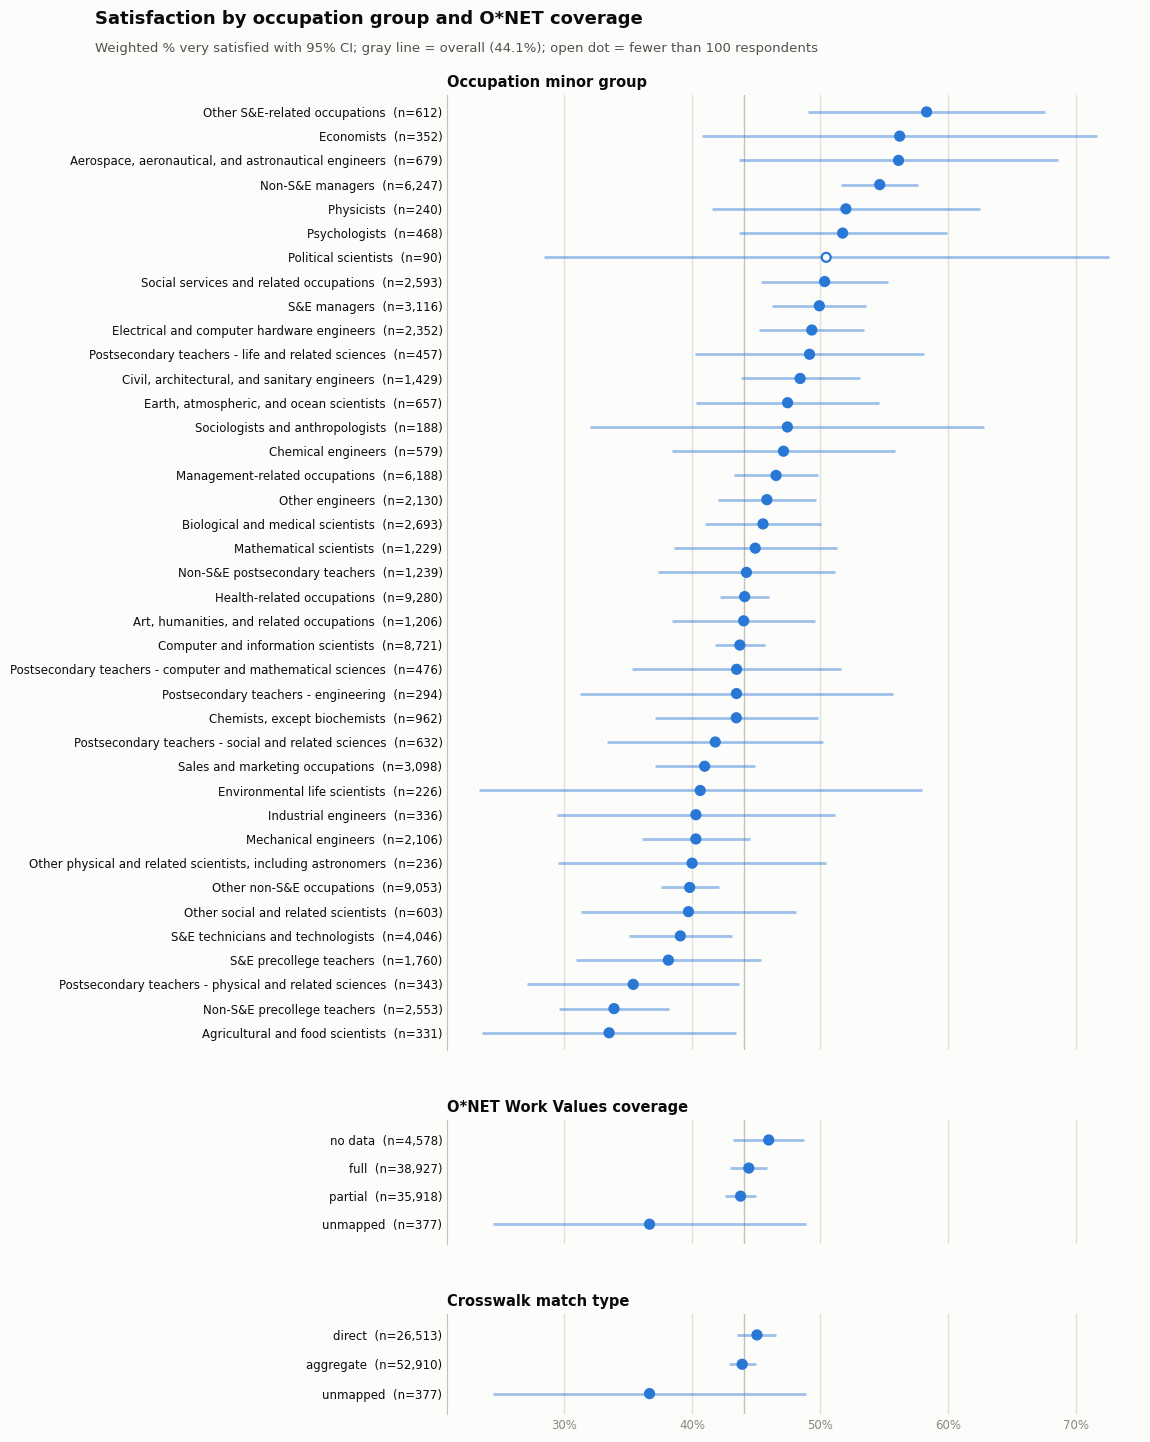

In [72]:
plot_segments(["Occupation minor group", "O*NET Work Values coverage", "Crosswalk match type"],
              "Satisfaction by occupation group and O*NET coverage", SUB)

### 13b. Fit preview: does a match between values and job relate to satisfaction?

For each importance item with a close O*NET counterpart, respondents are split two ways: whether they rate the factor **very important**, and whether their occupation scores **above or below the median** on the matching Work Value. If fit matters, the "very important" line should rise more steeply from low- to high-offer occupations than the other line.

O*NET Work Value definitions used for the pairing: Independence covers autonomy and responsibility; Recognition covers advancement and prestige; Working Conditions covers pay and job security; Achievement covers using one's abilities; Relationships covers serving others.

/var/folders/ny/p5hb2xbx46g25_c_0lg5mhyc0000gn/T/ipykernel_3446/3503080627.py:11: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  has_wv["_offer"] = np.where(has_wv[wv] > has_wv[wv].median(), "High", "Low")
/var/folders/ny/p5hb2xbx46g25_c_0lg5

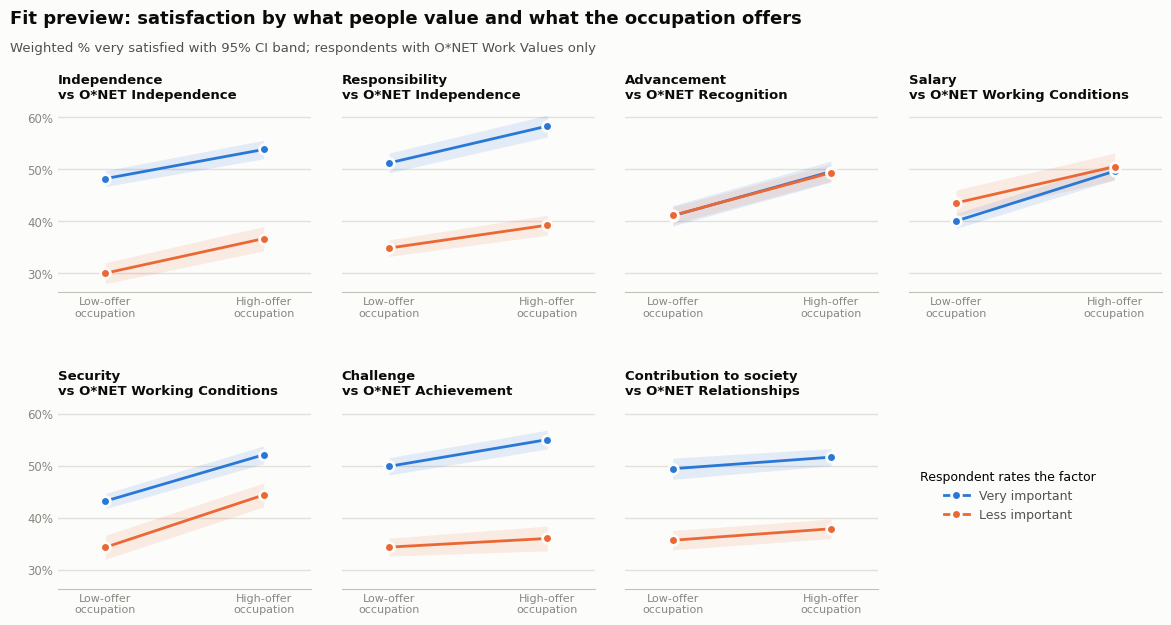

/opt/anaconda3/envs/myenv/lib/python3.14/site-packages/pandas/core/frame.py:5239: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  data[k] = com.apply_if_callable(v, data)


values,"gain from high-offer occupation, less important (pts)","gain from high-offer occupation, very important (pts)"
pair,,
Advancement / Recognition,8.2,8.5
Challenge / Achievement,1.7,5.1
Contribution to society / Relationships,2.2,2.2
Independence / Independence,6.6,5.6
Responsibility / Independence,4.4,7.1
Salary / Working Conditions,7.0,9.6
Security / Working Conditions,10.0,8.9


In [73]:
FIT_PAIRS = [("FACIND", "Independence"), ("FACRESP", "Independence"), ("FACADV", "Recognition"),
             ("FACSAL", "Working Conditions"), ("FACSEC", "Working Conditions"), ("FACCHAL", "Achievement"),
             ("FACSOC", "Relationships")]
SERIES = {True: ("Very important", "#2a78d6"), False: ("Less important", "#eb6834")}

has_wv = df[df.has_work_values].copy()
fit_rows = []
fig, axes = plt.subplots(2, 4, figsize=(12, 6.6), sharey=True, facecolor=SURFACE)
for ax, (fac, wv) in zip(axes.flat, FIT_PAIRS):
    style_ax(ax)
    has_wv["_offer"] = np.where(has_wv[wv] > has_wv[wv].median(), "High", "Low")
    has_wv["_values"] = has_wv[fac] == 4
    r = weighted_rate(has_wv, ["_values", "_offer"])
    for values, (label, color) in SERIES.items():
        sub = r.loc[values].reindex(["Low", "High"])
        ax.plot([0, 1], sub.pct, color=color, linewidth=2, marker="o", markersize=7,
                markeredgecolor=SURFACE, markeredgewidth=2, zorder=3, label=label)
        ax.fill_between([0, 1], sub.ci_low, sub.ci_high, color=color, alpha=0.12, linewidth=0)
        fit_rows.append({"pair": f"{FACTOR_NAMES[fac[3:]]} / {wv}", "values": label,
                         "low_offer_pct": sub.pct["Low"], "high_offer_pct": sub.pct["High"]})
    ax.set_title(f"{FACTOR_NAMES[fac[3:]]}\nvs O*NET {wv}", loc="left", color=INK, fontsize=9.5, fontweight="semibold")
    ax.set_xticks([0, 1])
    ax.set_xticklabels(["Low-offer\noccupation", "High-offer\noccupation"], color=MUTED, fontsize=8)
    ax.set_xlim(-0.3, 1.3)
    ax.yaxis.set_major_formatter(PercentFormatter(decimals=0))

legend_ax = axes.flat[-1]
legend_ax.axis("off")
legend_ax.legend(*axes.flat[0].get_legend_handles_labels(), loc="center left", frameon=False, fontsize=9,
                 labelcolor=INK_2, title="Respondent rates the factor", title_fontsize=9)

title_block(fig, "Fit preview: satisfaction by what people value and what the occupation offers",
            "Weighted % very satisfied with 95% CI band; respondents with O*NET Work Values only")
fig.subplots_adjust(left=0.06, right=0.98, top=0.83, bottom=0.1, hspace=0.6, wspace=0.12)
plt.show()

fit = pd.DataFrame(fit_rows).assign(gain_pts=lambda d: d.high_offer_pct - d.low_offer_pct)
fit.pivot(index="pair", columns="values", values="gain_pts").rename(
    columns=lambda c: f"gain from high-offer occupation, {c.lower()} (pts)").round(1)

**What this shows**

- **The biggest gaps** (spread between highest and lowest segment): occupation group (24.8 points, 33.5%-58.3%), telework situation (24.7), salary decile (23.4) and employer type (22.2).
- **Job and employer**: 49% of people whose job is closely related to their degree are very satisfied, against 36% when it's unrelated. Self-employed people (53-59%) are well above the private for-profit (42%) and local government (36%) rates. Small employers (10 or fewer staff, 55%) beat large ones (40-43%). Satisfaction climbs with salary, from 36-38% in the bottom three deciles to 59% in the top. Job zone rises from 34% (zone 2) to 47% (zone 5).
- **Telework is about choice**: people allowed to telework who chose not to are the most satisfied (59%), and those not allowed or required to the least (34%).
- **Background**: professional degrees (53%) lead bachelor's (42%). Native-born citizens (45%) are more satisfied than naturalized citizens (39%) and permanent residents (35%). Sex barely matters (43% vs 45%). The race/ethnicity extremes are the two smallest groups, with wide intervals.
- **O*NET coverage isn't strongly tied to satisfaction**: respondents with no Work Values (mostly software developers) are slightly above average (46%), so dropping them would slightly understate satisfaction. The 377 unmapped respondents are lower (37%) but the interval is wide.
- **Fit preview (13b)**: people who rate intrinsic factors very important are much more satisfied whatever their occupation offers (for independence, 48-54% against 30-37%), and high-offer occupations raise satisfaction for both groups (2-10 points). But the boost is only slightly larger for people who value the factor, and not consistently: larger for responsibility (7.1 vs 4.4 points), challenge (5.1 vs 1.7) and salary (9.6 vs 7.0); smaller for independence and security; equal for advancement and contribution to society. At this coarse level (median split, occupation-wide O*NET averages), fit shows only a weak signal. Finer fit measures, such as distances on the full scales, are the next thing to test.

## 14. Career-time trends

NSCG 2023 is a single survey year, so these "trends" compare people at different career stages, not the same people over time: years in the current job, years since the highest degree, and age. Two cautions when reading them:

- **Survivorship**: people who were unhappy in a job tend to leave it, so long-tenure groups are filtered toward the satisfied.
- **Cohort mixing**: older respondents differ from younger ones in degree field, occupation and era, not only career stage.

/var/folders/ny/p5hb2xbx46g25_c_0lg5mhyc0000gn/T/ipykernel_3446/2501521281.py:3: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  df["tenure_group"] = pd.cut(df.tenure_years, TENURE_BINS, labels=TENURE_LABELS)
/var/folders/ny/p5hb2xbx46g25_c_0l

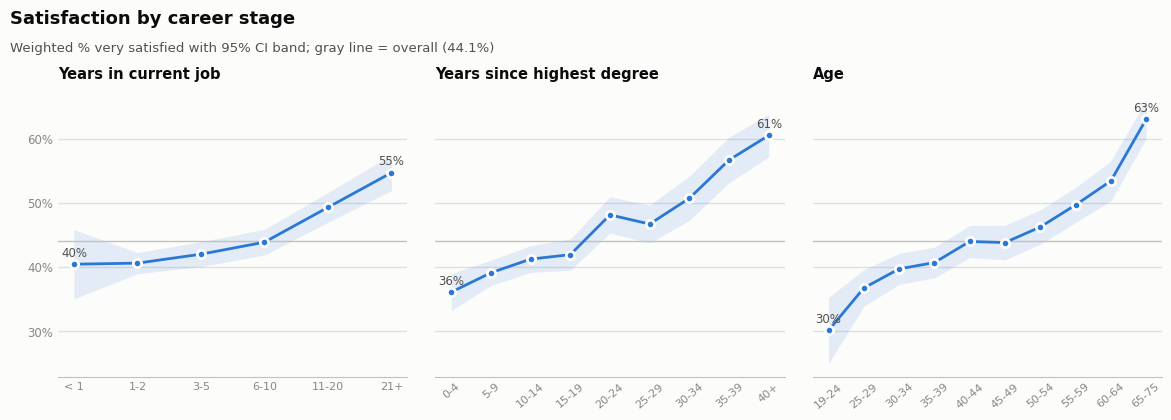

/var/folders/ny/p5hb2xbx46g25_c_0lg5mhyc0000gn/T/ipykernel_3446/1751323456.py:8: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  out["ci_low"], out["ci_high"] = out.pct - 1.96 * se, out.pct + 1.96 * se
/var/folders/ny/p5hb2xbx46g25_c_0lg5mhyc0

n   pct  ci_low  ci_high
Years in current job       < 1     2668  40.5    35.1     45.9
                           1-2    27498  40.6    39.0     42.3
                           3-5    18520  42.0    40.1     44.0
                           6-10   14164  43.9    41.9     45.9
                           11-20  10303  49.3    47.0     51.7
                           21+     6647  54.7    52.0     57.5
Years since highest degree 0-4    11431  36.1    33.2     39.0
                           5-9    19926  39.1    37.2     41.1
                           10-14  14808  41.3    39.2     43.4
                           15-19   8694  42.0    39.6     44.4
                           20-24   6591  48.2    45.3     51.0
                           25-29   6054  46.7    43.8     49.7
                           30-34   4678  50.8    47.3     54.2
                           35-39   3652  56.7    53.2     60.3
                           40+     3966  60.6    57.2     63.9
Age                        19-24   3706  30.2    25.0     35.3
                           25-29  10398  36.8    33.9     39.6
                           30-34  15660  39.8    37.3     42.2
                           35-39  11680  40.7    38.3     43.1
                           40-44   7741  44.0    41.5     46.5
                           45-49   7203  43.9    41.2     46.5
                           50-54   7009  46.3    43.6     48.9
                           55-59   6357  49.7    47.0     52.4
                           60-64   5119  53.5    50.3     56.6
                           65-75   4927  63.1    60.1     66.1

In [74]:
TENURE_BINS = [-1, 0, 2, 5, 10, 20, 60]
TENURE_LABELS = ["< 1", "1-2", "3-5", "6-10", "11-20", "21+"]
df["tenure_group"] = pd.cut(df.tenure_years, TENURE_BINS, labels=TENURE_LABELS)
df["degree_age_group"] = pd.cut(df.years_since_degree, [-1, 4, 9, 14, 19, 24, 29, 34, 39, 61],
                                labels=["0-4", "5-9", "10-14", "15-19", "20-24", "25-29", "30-34", "35-39", "40+"])
df["age_group"] = pd.cut(df.AGE, [18, 24, 29, 34, 39, 44, 49, 54, 59, 64, 75],
                         labels=["19-24", "25-29", "30-34", "35-39", "40-44", "45-49", "50-54", "55-59", "60-64", "65-75"])

CAREER = [("tenure_group", "Years in current job"), ("degree_age_group", "Years since highest degree"),
          ("age_group", "Age")]

fig, axes = plt.subplots(1, 3, figsize=(12, 4.6), sharey=True, facecolor=SURFACE)
for ax, (col, label) in zip(axes, CAREER):
    style_ax(ax)
    r = weighted_rate(df, col)
    x = np.arange(len(r))
    ax.fill_between(x, r.ci_low, r.ci_high, color=ACCENT, alpha=0.12, linewidth=0)
    ax.plot(x, r.pct, color=ACCENT, linewidth=2, marker="o", markersize=6, markeredgecolor=SURFACE,
            markeredgewidth=2, zorder=3)
    ax.axhline(OVERALL, color=BASELINE, linewidth=1, zorder=1)
    ax.set_xticks(x)
    ax.set_xticklabels(r.index, color=MUTED, fontsize=8, rotation=40 if len(r) > 6 else 0)
    ax.set_title(label, loc="left", color=INK, fontsize=10.5, fontweight="semibold")
    ax.yaxis.set_major_formatter(PercentFormatter(decimals=0))
    for xi, v in [(0, r.pct.iloc[0]), (len(r) - 1, r.pct.iloc[-1])]:
        ax.text(xi, v + 1.2, f"{v:.0f}%", ha="center", color=INK_2, fontsize=8.5)

title_block(fig, "Satisfaction by career stage",
            f"Weighted % very satisfied with 95% CI band; gray line = overall ({OVERALL:.1f}%)")
fig.subplots_adjust(left=0.06, right=0.98, top=0.8, bottom=0.17, wspace=0.08)
plt.show()

pd.concat({label: weighted_rate(df, col)[["n", "pct", "ci_low", "ci_high"]] for col, label in CAREER}).round(1)

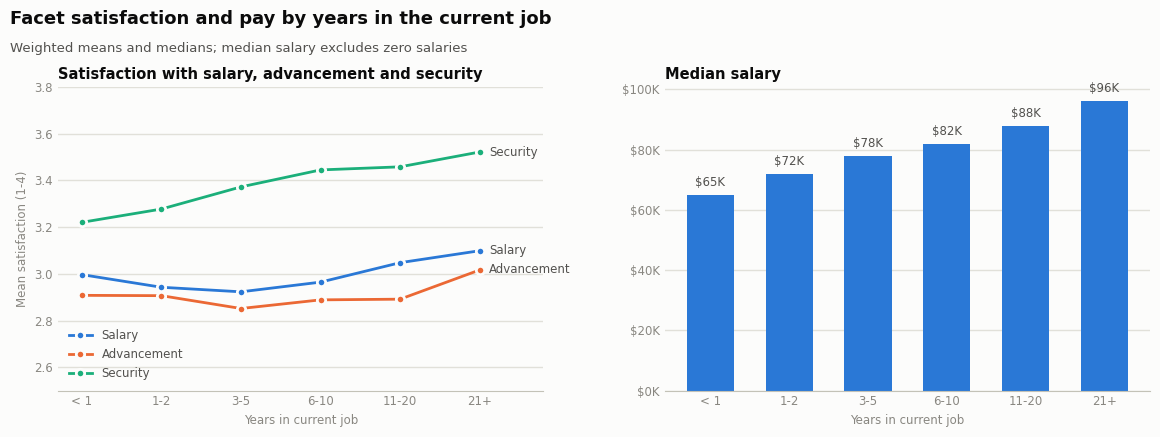

In [75]:
def weighted_mean(frame, by, col, w="WTSURVY"):
    tmp = frame.assign(_wx=frame[col] * frame[w])
    g = tmp.groupby(by, observed=True)
    return g._wx.sum() / g[w].sum()


def weighted_median(frame, by, col, w="WTSURVY"):
    def med(d):
        d = d.sort_values(col)
        return d[col].values[np.searchsorted(d[w].cumsum().values, d[w].sum() / 2)]
    return pd.Series({k: med(g) for k, g in frame.groupby(by, observed=True)})


FACET_SERIES = [("SATSAL", "Salary", "#2a78d6"), ("SATADV", "Advancement", "#eb6834"),
                ("SATSEC", "Security", "#1baf7a")]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.6), facecolor=SURFACE, gridspec_kw={"wspace": 0.25})
style_ax(ax1)
x = np.arange(len(TENURE_LABELS))
for col, label, color in FACET_SERIES:
    m = weighted_mean(df, "tenure_group", col)
    ax1.plot(x, m.values, color=color, linewidth=2, marker="o", markersize=6, markeredgecolor=SURFACE,
             markeredgewidth=2, zorder=3, label=label)
    ax1.text(x[-1] + 0.12, m.values[-1], label, color=INK_2, fontsize=8.5, va="center")
ax1.set_xticks(x)
ax1.set_xticklabels(TENURE_LABELS, color=MUTED)
ax1.set_xlim(-0.3, len(x) - 0.2)
ax1.set_ylim(2.5, 3.8)
ax1.set_ylabel("Mean satisfaction (1-4)", color=MUTED, fontsize=8.5)
ax1.set_xlabel("Years in current job", color=MUTED, fontsize=8.5)
ax1.set_title("Satisfaction with salary, advancement and security", loc="left", color=INK, fontsize=10.5, fontweight="semibold")
ax1.legend(frameon=False, fontsize=8.5, labelcolor=INK_2, loc="lower left")

style_ax(ax2)
med_sal = weighted_median(df[~df.salary_zero], "tenure_group", "SALARY")
ax2.bar(x, med_sal.values, width=0.6, color=ACCENT, zorder=2)
for xi, v in zip(x, med_sal.values):
    ax2.text(xi, v + 2000, f"${v / 1000:.0f}K", ha="center", va="bottom", color=INK_2, fontsize=8.5)
ax2.set_xticks(x)
ax2.set_xticklabels(TENURE_LABELS, color=MUTED)
ax2.yaxis.set_major_formatter(lambda v, _: f"${v / 1000:.0f}K")
ax2.set_xlabel("Years in current job", color=MUTED, fontsize=8.5)
ax2.set_title("Median salary", loc="left", color=INK, fontsize=10.5, fontweight="semibold")

title_block(fig, "Facet satisfaction and pay by years in the current job",
            "Weighted means and medians; median salary excludes zero salaries")
fig.subplots_adjust(left=0.06, right=0.97, top=0.8, bottom=0.14)
plt.show()

**What this shows**

- **Satisfaction rises with every career-time measure.** By tenure it goes from 40.5% (under 1 year) to 54.7% (21+ years), by years since highest degree from 36.1% (0-4) to 60.6% (40+), and by age from 30.2% (19-24) to 63.1% (65-75).
- **Tenure is flat for the first five years** (40-42%) and rises after that, consistent with survivorship: people who stay long in a job are disproportionately those who like it.
- **Facets**: satisfaction with security rises steadily with tenure (3.22 to 3.52 on the 1-4 scale). Salary and advancement satisfaction dip slightly at 3-5 years before rising, even though median salary climbs throughout (\$65K to \$96K).
- **The three measures overlap**: age and years since degree correlate at 0.84, and each correlates 0.44 with tenure. A model should use one or two of them, or check collinearity, rather than all three as independent effects.

## 15. Summary

**Data quality**

- 79,800 employed respondents, 71+ columns, 99.4% of values present; no duplicates, no invalid values and no consistency violations (sections 1-5).
- Gaps are almost all on the O*NET side: Work Values missing for 3.9% of respondents (weighted), mostly software developers; Job Zone for 0.8%. These are flagged, not filled.
- Salary and earnings are top-coded above \$500k (about 0.5% of rows), and 499 salaries are zero or under \$1,000; all flagged.
- Survey weights are extremely uneven: the effective sample size is about 11,400, so weighted figures carry wider uncertainty than n = 79,800 suggests.

**Relationships with satisfaction**

1. **The satisfaction facets** (`SAT*`) are by far the strongest correlates (0.29-0.50), confirming they must stay out of the features.
2. **Career stage** has the clearest gradient: from 30% very satisfied at ages 19-24 to 63% at 65-75, with similar rises by tenure and years since degree. Part of this is survivorship.
3. **Job context** matters more than demographics: occupation group, telework situation, salary, employer type and job-degree relatedness each span 13-25 points; sex and degree field span 2-6.
4. **What people value** (`FAC*`) is weakly related on its own (at most 0.17, intrinsic factors strongest), is compressed near the top of the scale, and forms two clusters (extrinsic: salary, benefits, security; intrinsic: challenge, responsibility, independence, society).
5. **Person and job sides are nearly independent** (importance vs O*NET Work Values below 0.11, except society vs Relationships at 0.21), so fit features can add information. The coarse fit preview shows only a weak, inconsistent match effect; finer fit measures are the next step.

**For modeling**

- Use log salary plus the salary flags; group or target-encode occupation (129 codes) and industry (264 codes).
- Use a "very important" indicator or person-relative scores for the `FAC*` items, given the ceiling effect.
- Report weighted metrics and treat age, tenure and years since degree as overlapping.